# Atividade 4: contagem de moedas com YOLO11 e YOLO + ViT

Antes de rodar: ativar a GPU (T4) em Ambiente de execução > Alterar tipo de ambiente.

Sem moedas para fotografar, o dataset principal é sintético: `gerar_dataset.py` cola recortes de fotos reais de
moedas (`moedas_base/`, Wikimedia Commons, domínio público ou CC0) sobre fundos de mesa, com rotação, sombra, luz
e tamanho variados. São 200 imagens com 5 a 40 moedas cada: 140 de treino, 40 de validação e 20 de teste.
Como o gerador sabe onde pôs cada moeda, as caixas e o total em reais são exatos.

As fotos reais vêm do Brazilian Coin Detection Dataset (CC BY 4.0, ver `reais/FONTES.md`), separadas por
`preparar_reais.py`, cada uma de uma sessão de fotos diferente:
- `reais/teste/`: 10 fotos, nunca usadas no treino, que medem o desempenho em fotos de verdade;
- `reais/treino/` e `reais/valid/`: as fotos com mais moedas entre as restantes, usadas numa segunda etapa de
  transfer learning (o modelo treinado no sintético é ajustado com fotos reais);
- `reais/demo/`: 3 fotos para a demonstração.

O transfer learning acontece em duas etapas: pesos do COCO → dataset sintético → fotos reais.

As classes do sintético são por valor e face (`5c_valor`, `5c_efigie`, ..., `1real_efigie`). A versão com uma
classe por valor (`5c`, ..., `1real`) é gerada aqui a partir dela, sem anotar de novo. As fotos reais estão
anotadas só por valor.

In [1]:
!pip install -q ultralytics datasets

# Valor em reais de cada classe. O total da foto é a soma destes valores, então é daqui que sai a métrica
# que mais importa na atividade (o erro no total em R$).
VALORES = {"5c": 0.05, "10c": 0.10, "25c": 0.25, "50c": 0.50, "1real": 1.00}
# Classes por valor, na ordem do dicionário. Essa ordem define o índice de cada classe nos rótulos YOLO
# "por valor" e precisa ser a mesma usada em preparar_reais.py, que anota as fotos reais.
CLASSES = list(VALORES)

## Parte A: dados

In [2]:
# Clona o repositório para ter o gerador e as fotos reais já separadas. O dataset sintético é gerado aqui, e
# não baixado pronto, para que qualquer pessoa reproduza exatamente as mesmas imagens (o gerador usa semente fixa).
!git clone -q --depth 1 https://github.com/data-science-unicamp/aplicacoes-data-science /content/repo
!cd /content/repo/atividade4 && python gerar_dataset.py
!rm -rf /content/por_face && cp -r /content/repo/atividade4/dataset /content/por_face

train 140 imagens
valid 40 imagens
test 20 imagens


In [3]:
# Cria a versão "por valor" do dataset sintético. Em vez de anotar de novo, copia o dataset e troca cada classe
# "10c_valor" ou "10c_efigie" por "10c": as caixas são as mesmas, só muda o que o modelo precisa distinguir.
# Assim as duas definições de classes da Parte A são comparadas com exatamente as mesmas imagens e caixas.
import os, glob, shutil, yaml

face = yaml.safe_load(open("/content/por_face/data.yaml"))
shutil.copytree("/content/por_face", "/content/por_valor", dirs_exist_ok=True)
for lbl in glob.glob("/content/por_valor/*/labels/*.txt"):
    linhas = []
    for linha in open(lbl).read().splitlines():
        c, *v = linha.split()
        # "10c_efigie".split("_")[0] -> "10c"; o novo índice é a posição de "10c" em CLASSES
        linhas.append(" ".join([str(CLASSES.index(face["names"][int(c)].split("_")[0]))] + v))
    open(lbl, "w").write("\n".join(linhas))

# O Ultralytics procura as imagens pelos caminhos do data.yaml; caminhos absolutos evitam que ele os resolva em
# relação a outra pasta e não encontre as imagens.
for nome, names in [("por_face", face["names"]), ("por_valor", CLASSES)]:
    root = f"/content/{nome}"
    cfg = {"train": f"{root}/train/images", "val": f"{root}/valid/images", "test": f"{root}/test/images",
           "nc": len(names), "names": names}
    yaml.safe_dump(cfg, open(f"{root}/data.yaml", "w"))
    print(nome, cfg["names"])

por_face ['5c_valor', '5c_efigie', '10c_valor', '10c_efigie', '25c_valor', '25c_efigie', '50c_valor', '50c_efigie', '1real_valor', '1real_efigie']
por_valor ['5c', '10c', '25c', '50c', '1real']


In [4]:
# Quantidade de imagens e de moedas por classe em cada conjunto, para a tabela do relatório. Serve também para
# conferir se as classes estão equilibradas: uma classe com poucas moedas tende a ser a mais errada.
import pandas as pd
from collections import Counter

tabela = {}
for split in ["train", "valid", "test"]:
    cont = Counter()
    for lbl in glob.glob(f"/content/por_face/{split}/labels/*.txt"):
        cont.update(face["names"][int(l.split()[0])] for l in open(lbl).read().splitlines())
    cont["imagens"] = len(glob.glob(f"/content/por_face/{split}/images/*"))
    tabela[split] = cont
pd.DataFrame(tabela).fillna(0).astype(int)

,train,valid,test
1real_valor,325,86,29
1real_efigie,325,83,38
10c_efigie,310,87,45
10c_valor,331,80,39
5c_efigie,296,88,34
5c_valor,270,88,35
50c_valor,340,111,43
25c_valor,314,90,55
50c_efigie,314,99,50
25c_efigie,287,83,33


## Parte A: treino (transfer learning, 1a etapa: dataset sintético)

Dois modelos `yolo11s` partindo dos pesos do COCO, um para cada definição de classes. `imgsz=960` porque as
moedas são objetos pequenos. Augmentation no treino: além do padrão do Ultralytics (brilho, contraste, escala,
espelhamento horizontal e mosaico), rotação de até 180 graus e espelhamento vertical, já que moeda não tem
orientação fixa.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/por_face/data.yaml, degrees=180, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, fre

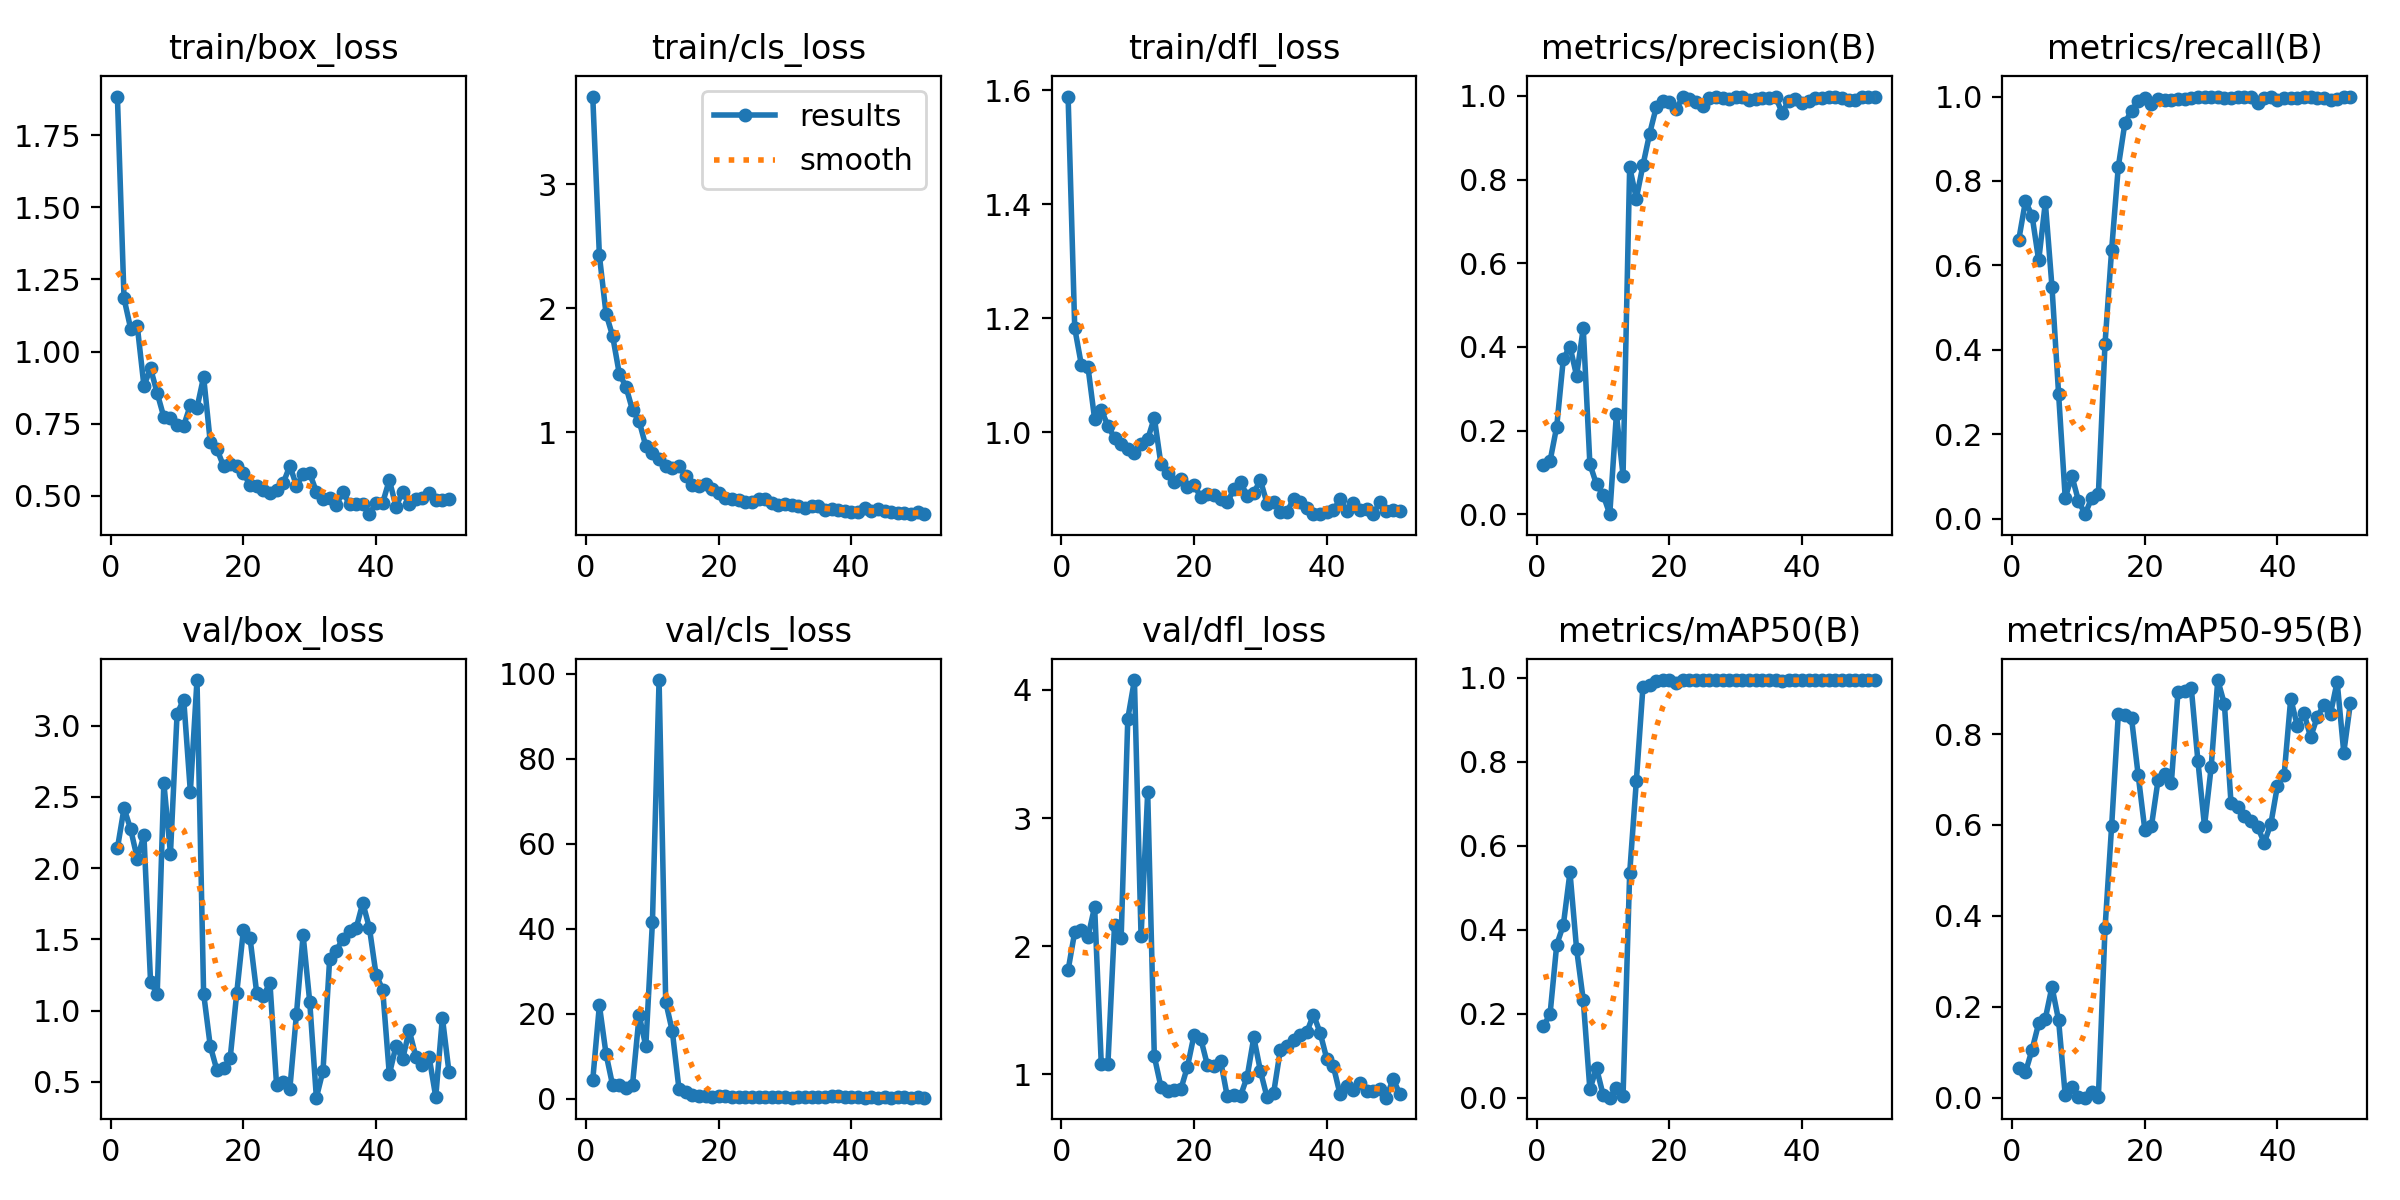

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/por_valor/data.yaml, degrees=180, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=por_valor, nbs=64, nms=None, opset=None, optimize=False, opt

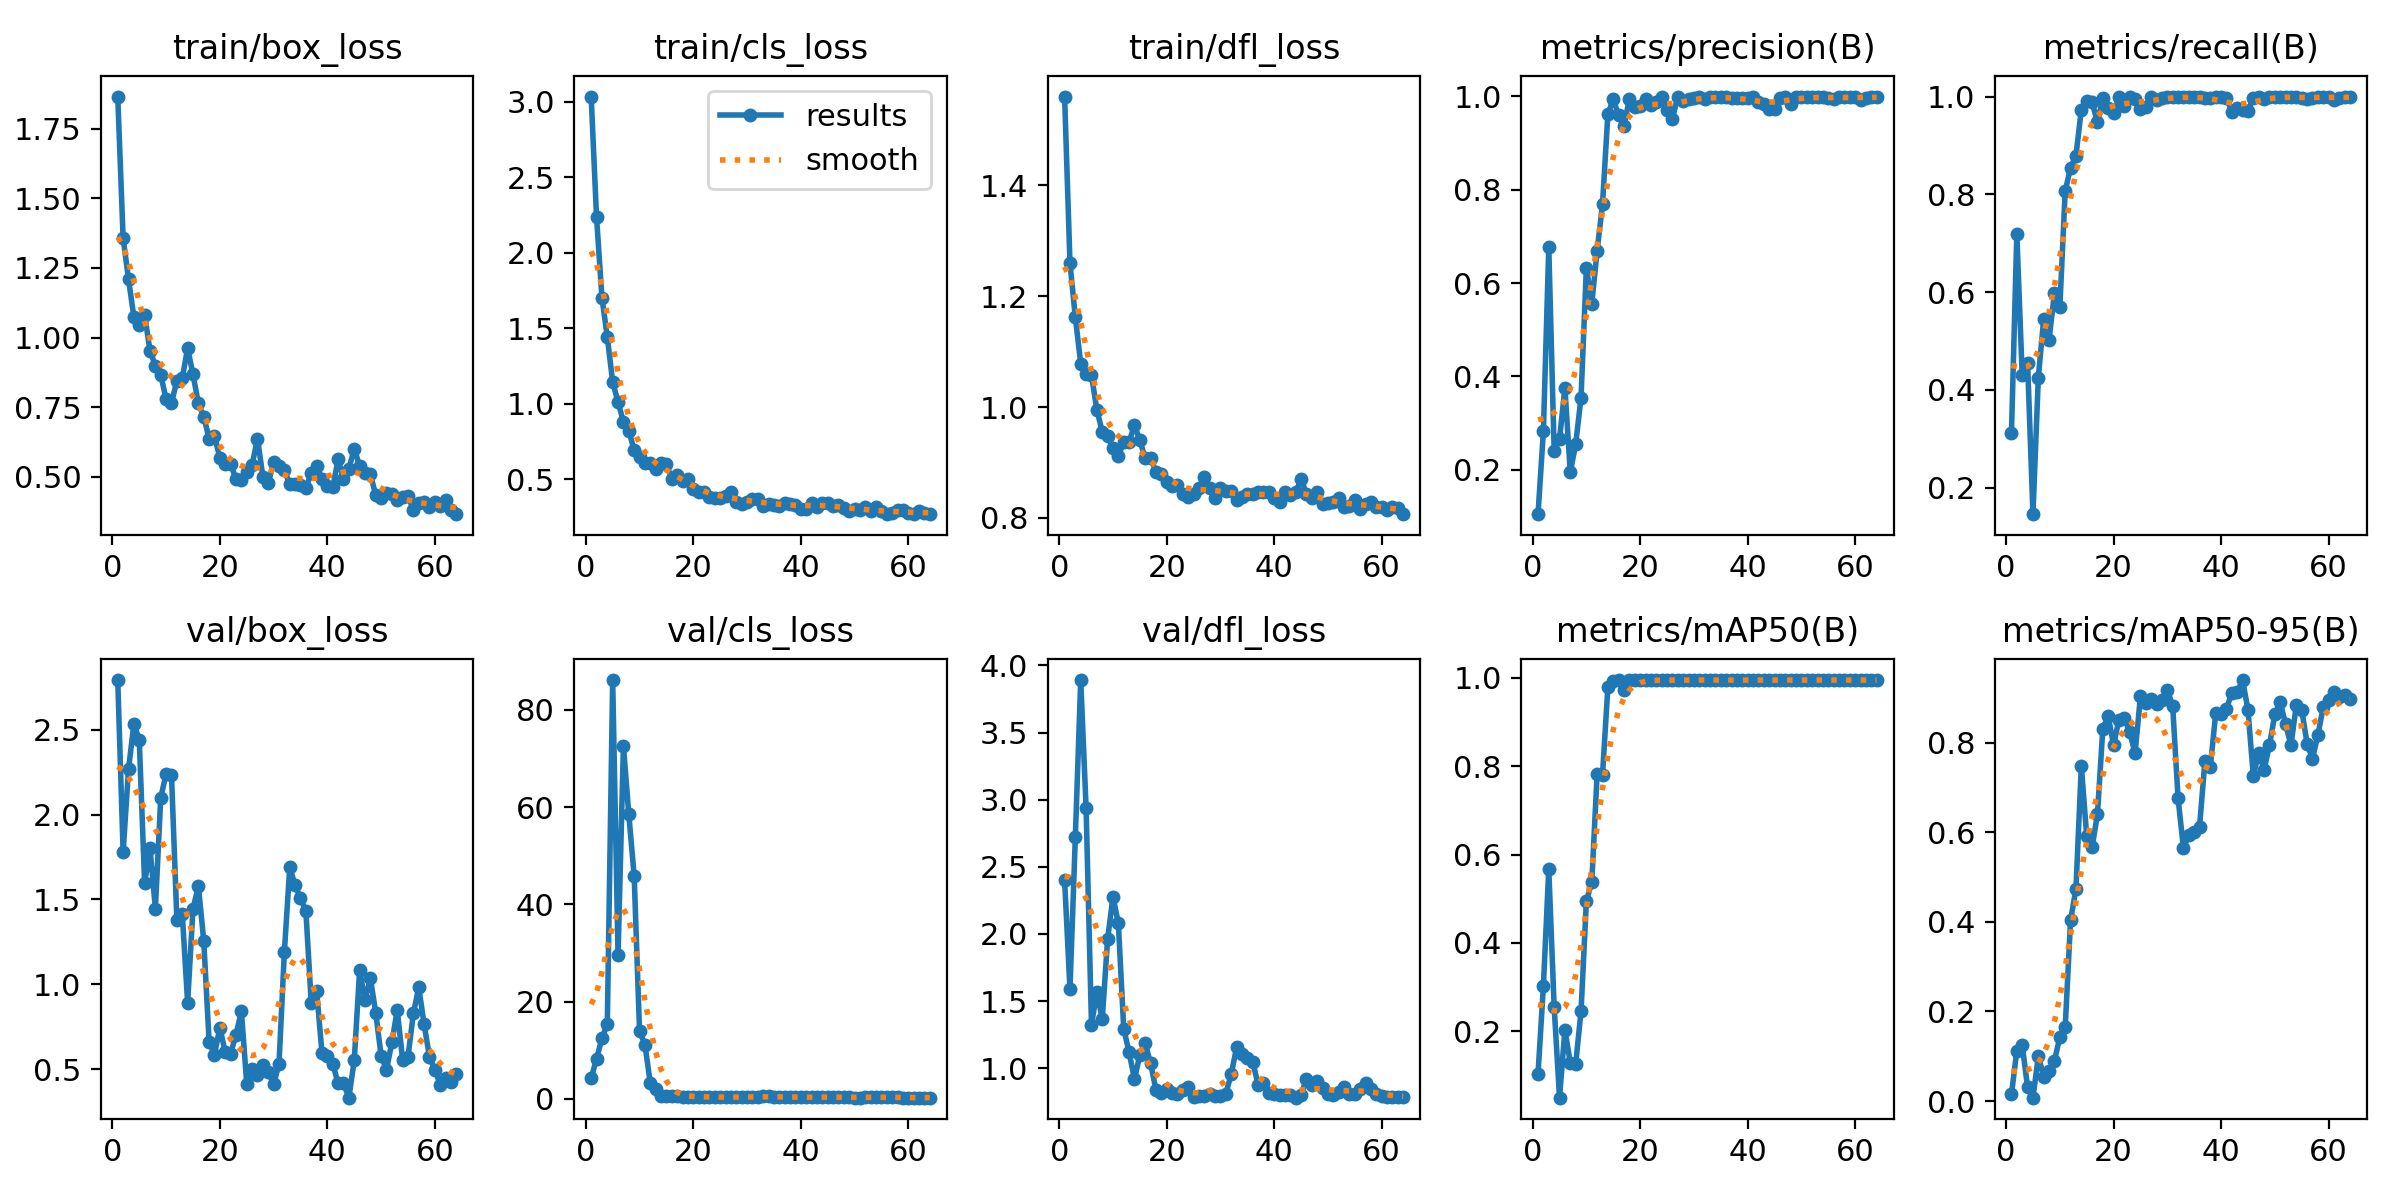

In [5]:
from ultralytics import YOLO
from IPython.display import Image, display

modelos = {}
for nome in ["por_face", "por_valor"]:
    # Transfer learning: parte dos pesos treinados no COCO, que já sabem achar bordas, formas e
    # objetos, e ajusta todas as camadas para as moedas. Treinar do zero exigiria muito mais imagens.
    model = YOLO("yolo11s.pt")
    # imgsz=960: as moedas ocupam poucos pixels nas fotos com até 40 moedas, e uma resolução maior preserva os
    #   detalhes que separam 10c de 25c e uma face da outra.
    # degrees=180 e flipud=0.5: uma moeda pode aparecer em qualquer rotação na mesa, então o modelo não deve
    #   depender da orientação.
    # patience=20: para o treino quando o mAP da validação não melhora por 20 épocas, evitando overfitting e
    #   tempo de GPU desperdiçado; o best.pt guarda a melhor época.
    model.train(data=f"/content/{nome}/data.yaml", epochs=100, imgsz=960, batch=16, patience=20,
                degrees=180, flipud=0.5, project="/content/runs", name=nome, exist_ok=True)
    modelos[nome] = YOLO(f"/content/runs/{nome}/weights/best.pt")
    display(Image(f"/content/runs/{nome}/results.png", width=900))  # curvas de perda e métricas por época

## Parte A: avaliação no conjunto de teste

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,416,670 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 28.2±18.4 MB/s, size: 188.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/por_face/test/labels... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 531.3it/s 0.0s
val: New cache created: /content/por_face/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.7it/s 1.2s
                   all         20        401      0.996      0.999      0.995      0.911
              5c_valor         15         35      0.997          1      0.995      0.892
             5c_efigie         15         34      0.997          1      0.995      0.935
             10c_val

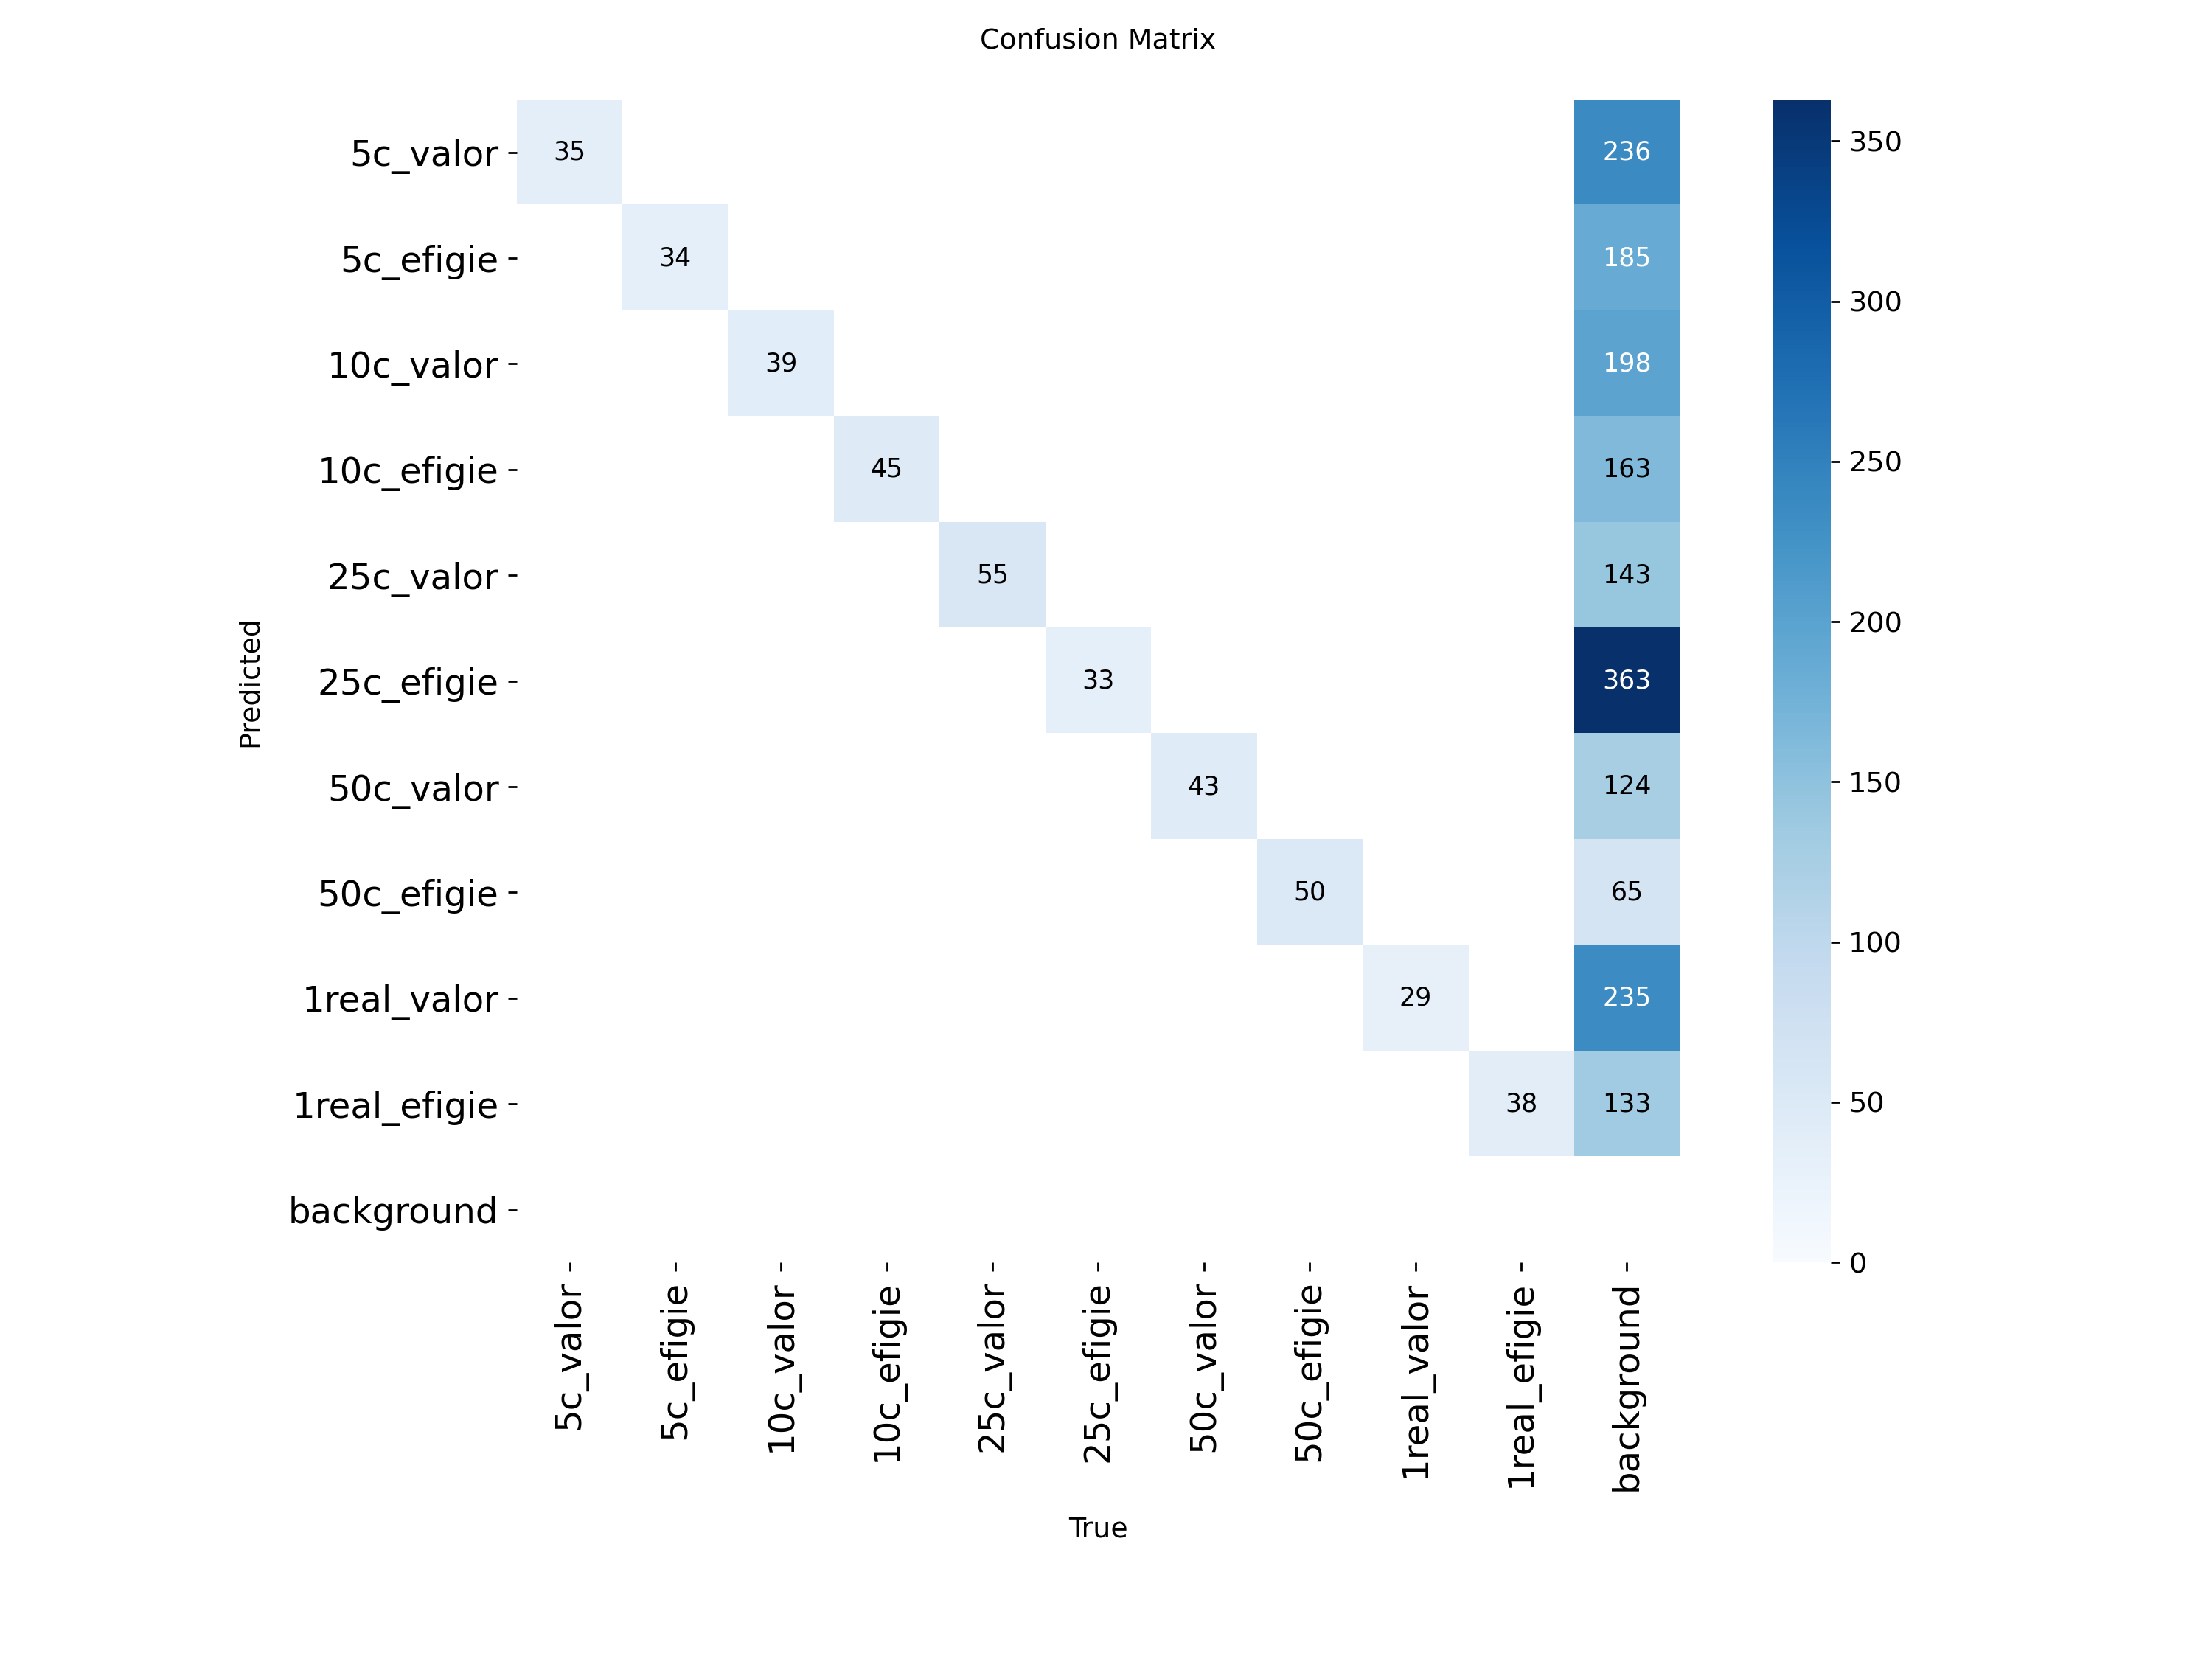

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,414,735 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 75.1±59.1 MB/s, size: 131.3 KB)
val: Scanning /content/por_valor/test/labels... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 652.3it/s 0.0s
val: New cache created: /content/por_valor/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.1it/s 1.8s
                   all         20        401      0.978      0.975      0.995      0.943
                    5c         19         69          1      0.898      0.994      0.938
                   10c         19         84          1      0.978      0.995      0.951
                   25c         19         88      0.898          1      0.995      0.945
                   50c         20         93      0.995          1      0.995      0

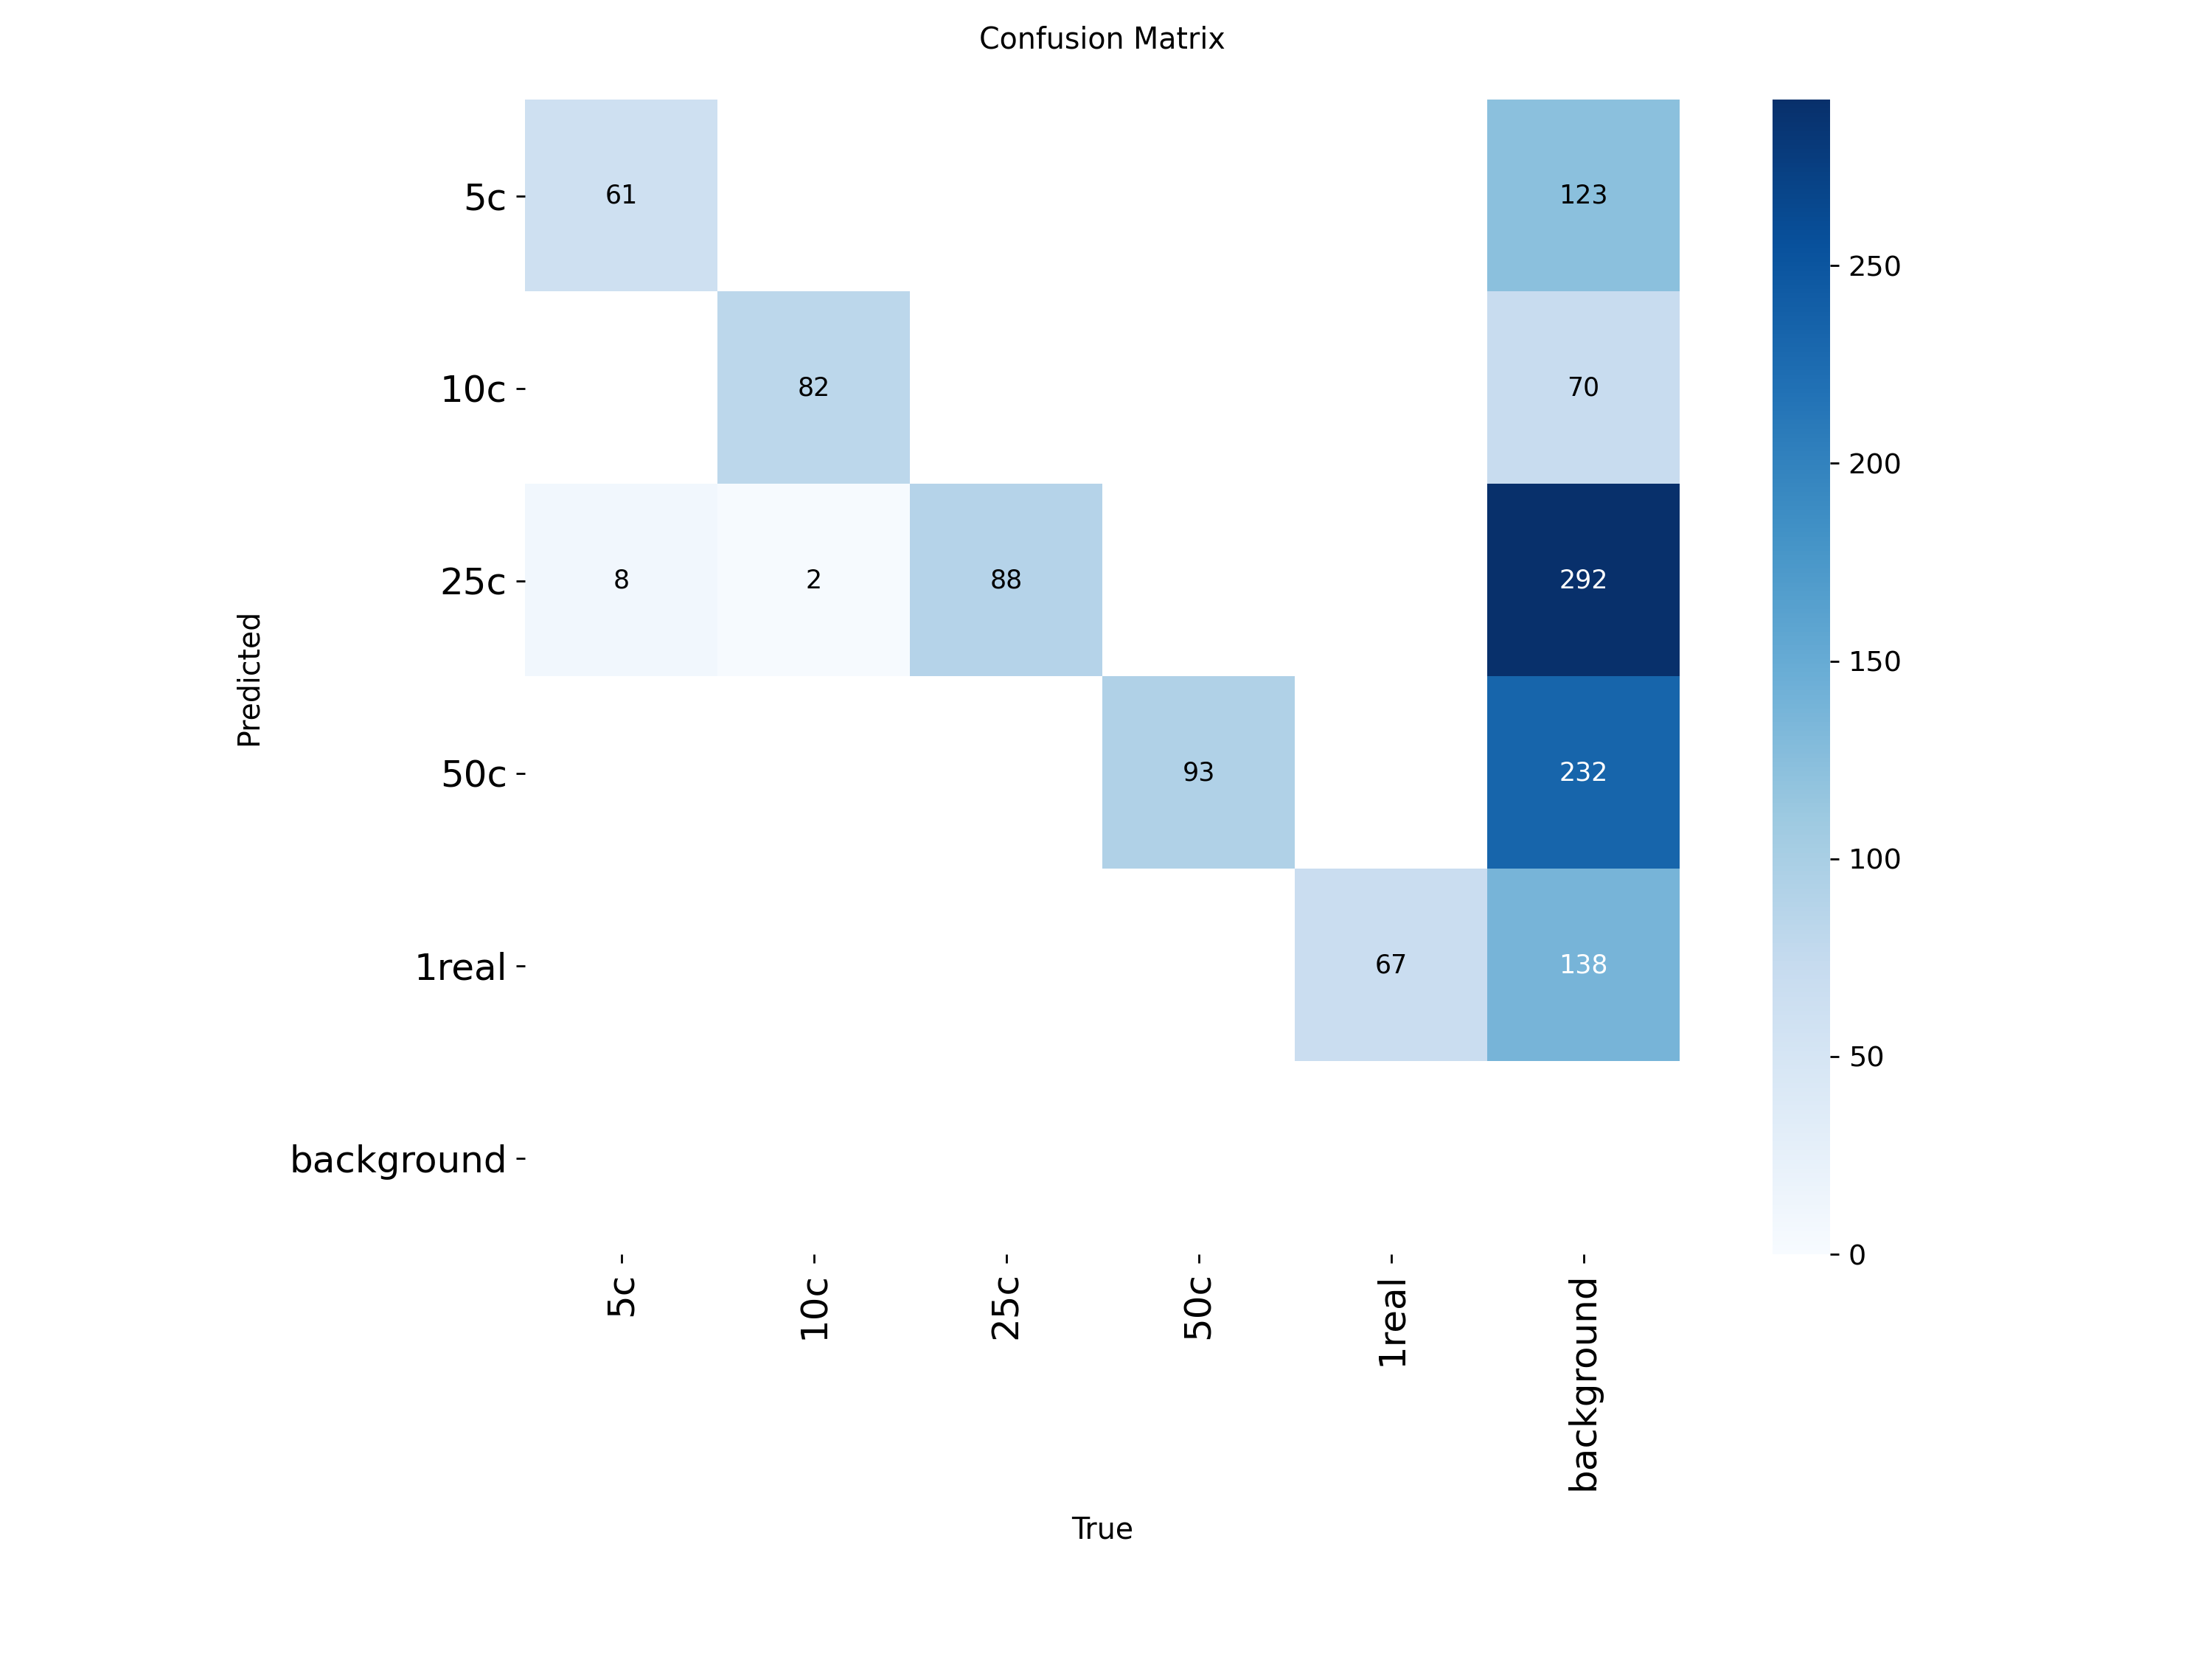

In [6]:
# mAP, precisão e revocação no teste sintético e matriz de confusão de cada modelo. O teste não foi visto no
# treino nem na escolha da melhor época, então mede a generalização dentro do domínio sintético.
metricas = {}
for nome, model in modelos.items():
    m = model.val(data=f"/content/{nome}/data.yaml", split="test", imgsz=960,
                  project="/content/runs", name=f"{nome}_teste", exist_ok=True)
    metricas[nome] = m.box.map50
    print(f"{nome}: mAP50 {m.box.map50:.3f} | mAP50-95 {m.box.map:.3f} | "
          f"precisão {m.box.mp:.3f} | revocação {m.box.mr:.3f}")
    display(Image(f"/content/runs/{nome}_teste/confusion_matrix.png", width=700))

In [7]:
# Avaliação pelo valor em reais. O mAP mede caixas, mas o objetivo da atividade é o total da foto, então cada
# foto é comparada com as caixas anotadas (o total real) por duas métricas: acurácia por moeda e erro no total.
import time, torch
from PIL import Image as PILImage
from torchvision.ops import box_iou

# Conjuntos avaliados: pasta e nomes das classes dos rótulos. O sintético está anotado por valor e face e as
# fotos reais só por valor; guardar os nomes junto com a pasta permite ler os dois com a mesma função.
REAIS = "/content/repo/atividade4/reais"
CONJUNTOS = {"valid": ("/content/por_face/valid", face["names"]), "test": ("/content/por_face/test", face["names"]),
             "reais_valid": (f"{REAIS}/valid", CLASSES), "reais": (f"{REAIS}/teste", CLASSES),
             "demo": (f"{REAIS}/demo", CLASSES)}

def rotulos(p, names):
    # Lê as caixas anotadas da foto e as converte do formato YOLO (centro, largura e altura relativos) para
    # x1 y1 x2 y2 em pixels, o formato das caixas previstas, para poder calcular a IoU entre elas.
    # Devolve também o valor de cada moeda ("10c_efigie" vira "10c"), que é o que importa para o total.
    w, h = PILImage.open(p).size
    caixas, classes = [], []
    for linha in open(p.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt").read().splitlines():
        c, xc, yc, bw, bh = linha.split()[:5]
        xc, yc, bw, bh = float(xc) * w, float(yc) * h, float(bw) * w, float(bh) * h
        caixas.append([xc - bw / 2, yc - bh / 2, xc + bw / 2, yc + bh / 2])
        classes.append(names[int(c)].split("_")[0])
    return caixas, classes

def avaliar(prever, conj):
    # prever(foto) -> (caixas, classes por valor). Recebe a função de previsão, e não o modelo, para que a mesma
    # avaliação sirva para o YOLO sozinho e para o pipeline YOLO + ViT da Parte B.
    # Devolve a acurácia por moeda, o erro médio no total (R$), o tempo por imagem e a tabela por foto.
    pasta, names = CONJUNTOS[conj]
    acertos = n = 0
    fotos = []
    for p in sorted(glob.glob(f"{pasta}/images/*")):
        t = time.perf_counter()
        caixas, classes = prever(p)
        ms = (time.perf_counter() - t) * 1000
        reais, classes_reais = rotulos(p, names)
        # Acurácia por moeda: cada moeda anotada casa com a caixa prevista de maior IoU (mínimo 0.5, o critério
        # usual de detecção) e conta como acerto se o valor previsto for o certo. Zerar a coluna da caixa usada
        # impede que uma única caixa seja contada para duas moedas. Moeda não detectada conta como erro.
        if caixas:
            iou = box_iou(torch.tensor(reais), torch.tensor(caixas))
            for i, c in enumerate(classes_reais):
                j = int(iou[i].argmax())
                if iou[i, j] >= 0.5:
                    acertos += classes[j] == c
                    iou[:, j] = 0
        n += len(classes_reais)
        # Erro no total: o que o usuário vê. Caixas a mais (duplicadas ou no fundo) e moedas perdidas aparecem
        # aqui mesmo quando a acurácia por moeda não as pega.
        previsto = sum(VALORES[c] for c in classes)
        real = sum(VALORES[c] for c in classes_reais)
        fotos.append({"foto": p, "real": real, "previsto": previsto,
                      "erro": abs(previsto - real), "ms": ms})
    fotos = pd.DataFrame(fotos)
    # O tempo ignora a 1a foto porque ela inclui o aquecimento da GPU, que não se repete no uso normal.
    return {"acuracia": acertos / n, "erro_medio": fotos["erro"].mean(),
            "ms": fotos["ms"].iloc[1:].mean(), "fotos": fotos}

def prever_yolo(model, conf):
    def prever(p):
        # agnostic_nms=True: a supressão de caixas sobrepostas (NMS) passa a valer entre classes diferentes.
        # Sem isso, o modelo por face às vezes marca a mesma moeda duas vezes (uma caixa "10c_valor" e outra
        # "10c_efigie"), e o valor da moeda entra duas vezes no total. Duas moedas não ocupam o mesmo lugar,
        # então manter só a caixa de maior confiança é sempre o certo.
        r = model.predict(p, conf=conf, imgsz=960, agnostic_nms=True, verbose=False)[0]
        return r.boxes.xyxy.tolist(), [model.names[int(c)].split("_")[0] for c in r.boxes.cls]
    return prever

def escolher_conf(fabrica, conj):
    # O limiar de confiança muda o total: baixo demais soma caixas falsas, alto demais perde moedas. Ele é
    # escolhido pelo menor erro num conjunto de VALIDAÇÃO, nunca no teste, para que o resultado do teste continue
    # sendo uma medida honesta. Modelos treinados só no sintético usam a validação sintética; os ajustados com
    # fotos reais usam a validação real, que é o tipo de foto em que serão usados.
    erros = {conf: avaliar(fabrica(conf), conj)["erro_medio"] for conf in [0.25, 0.4, 0.5, 0.6, 0.7]}
    print("erro médio (R$) na validação por conf:", {k: round(v, 3) for k, v in erros.items()})
    return min(erros, key=erros.get)

def avaliar_modelo(nome, prever_conf, conj_conf):
    # Escolhe o conf, guarda a função de previsão e avalia no teste sintético e nas 10 fotos reais de teste.
    confs[nome] = escolher_conf(prever_conf, conj_conf)
    previsores[nome] = prever_conf(confs[nome])
    resultados[nome] = avaliar(previsores[nome], "test")
    reais[nome] = avaliar(previsores[nome], "reais")
    for conj, r in [("teste sintético", resultados[nome]), ("fotos reais", reais[nome])]:
        print(f"{nome} ({conj}): conf {confs[nome]} | acurácia por moeda {r['acuracia']:.3f} | "
              f"erro médio no total R$ {r['erro_medio']:.2f}")
        display(r["fotos"])

resultados, reais, confs, previsores = {}, {}, {}, {}
for nome, model in modelos.items():
    # model=model fixa o modelo desta volta do laço; sem isso a função usaria o último modelo do laço.
    avaliar_modelo(nome, lambda conf, model=model: prever_yolo(model, conf), "valid")

erro médio (R$) na validação por conf: {0.25: np.float64(0.0), 0.4: np.float64(0.0), 0.5: np.float64(0.0), 0.6: np.float64(0.0), 0.7: np.float64(0.0)}
por_face (teste sintético): conf 0.25 | acurácia por moeda 1.000 | erro médio no total R$ 0.00


,foto,real,previsto,erro,ms
0,/content/por_face/test/images/test_000.jpg,2.15,2.15,0.0,26.215916
1,/content/por_face/test/images/test_001.jpg,4.10,4.10,0.0,27.817693
2,/content/por_face/test/images/test_002.jpg,6.70,6.70,0.0,28.377743
3,/content/por_face/test/images/test_003.jpg,2.90,2.90,0.0,25.904501
4,/content/por_face/test/images/test_004.jpg,1.90,1.90,0.0,24.982259
5,/content/por_face/test/images/test_005.jpg,4.45,4.45,0.0,26.412451
6,/content/por_face/test/images/test_006.jpg,14.65,14.65,0.0,29.262286
7,/content/por_face/test/images/test_007.jpg,11.20,11.20,0.0,29.191738
8,/content/por_face/test/images/test_008.jpg,9.60,9.60,0.0,27.037002
9,/content/por_face/test/images/test_009.jpg,10.95,10.95,0.0,27.691217


por_face (fotos reais): conf 0.25 | acurácia por moeda 0.519 | erro médio no total R$ 1.10


,foto,real,previsto,erro,ms
0,/content/repo/atividade4/reais/teste/images/10...,1.00,1.65,0.65,28.782825
1,/content/repo/atividade4/reais/teste/images/10...,1.00,1.35,0.35,27.953238
2,/content/repo/atividade4/reais/teste/images/12...,1.20,1.90,0.70,22.828982
3,/content/repo/atividade4/reais/teste/images/12...,1.20,1.65,0.45,22.444346
4,/content/repo/atividade4/reais/teste/images/13...,1.30,6.40,5.10,21.407372
5,/content/repo/atividade4/reais/teste/images/14...,1.45,2.15,0.70,22.195061
6,/content/repo/atividade4/reais/teste/images/15...,1.50,3.45,1.95,22.874038
7,/content/repo/atividade4/reais/teste/images/17...,1.70,1.75,0.05,23.453516
8,/content/repo/atividade4/reais/teste/images/17...,1.75,2.45,0.70,23.830914
9,/content/repo/atividade4/reais/teste/images/75...,0.75,1.10,0.35,22.504419


erro médio (R$) na validação por conf: {0.25: np.float64(0.128), 0.4: np.float64(0.128), 0.5: np.float64(0.128), 0.6: np.float64(0.121), 0.7: np.float64(0.103)}
por_valor (teste sintético): conf 0.7 | acurácia por moeda 0.965 | erro médio no total R$ 0.07


,foto,real,previsto,erro,ms
0,/content/por_face/test/images/test_000.jpg,2.15,2.15,0.00,25.096869
1,/content/por_face/test/images/test_001.jpg,4.10,4.10,0.00,25.804372
2,/content/por_face/test/images/test_002.jpg,6.70,6.90,0.20,30.023328
3,/content/por_face/test/images/test_003.jpg,2.90,2.90,0.00,28.991212
4,/content/por_face/test/images/test_004.jpg,1.90,1.90,0.00,24.120302
5,/content/por_face/test/images/test_005.jpg,4.45,4.80,0.35,26.929279
6,/content/por_face/test/images/test_006.jpg,14.65,14.75,0.10,28.701616
7,/content/por_face/test/images/test_007.jpg,11.20,11.20,0.00,29.043202
8,/content/por_face/test/images/test_008.jpg,9.60,9.60,0.00,27.666701
9,/content/por_face/test/images/test_009.jpg,10.95,11.15,0.20,27.450284


por_valor (fotos reais): conf 0.7 | acurácia por moeda 0.256 | erro médio no total R$ 1.55


,foto,real,previsto,erro,ms
0,/content/repo/atividade4/reais/teste/images/10...,1.00,2.55,1.55,22.912585
1,/content/repo/atividade4/reais/teste/images/10...,1.00,2.85,1.85,21.659772
2,/content/repo/atividade4/reais/teste/images/12...,1.20,2.45,1.25,21.324563
3,/content/repo/atividade4/reais/teste/images/12...,1.20,2.35,1.15,21.454431
4,/content/repo/atividade4/reais/teste/images/13...,1.30,3.75,2.45,22.488361
5,/content/repo/atividade4/reais/teste/images/14...,1.45,2.20,0.75,22.942125
6,/content/repo/atividade4/reais/teste/images/15...,1.50,4.60,3.10,23.423973
7,/content/repo/atividade4/reais/teste/images/17...,1.70,2.70,1.00,23.053840
8,/content/repo/atividade4/reais/teste/images/17...,1.75,2.75,1.00,22.251014
9,/content/repo/atividade4/reais/teste/images/75...,0.75,2.15,1.40,21.806136


## Transfer learning, 2a etapa: fotos reais

O resultado nas fotos reais fica bem abaixo do sintético: o modelo só viu 20 recortes de moedas colados em fundos
artificiais e nunca uma foto de celular. Para reduzir essa diferença, o YOLO "por valor" já treinado no sintético
passa por uma segunda etapa de transfer learning, com as fotos reais que têm mais moedas (fora das
sessões de teste e de demonstração e das próximas a elas) somadas ao treino sintético. O sintético continua no treino porque traz
moedas de 25c, 50c e 1 real, raras nas fotos reais, e evita que o modelo esqueça o que aprendeu na 1a etapa.

Só o modelo por valor passa por esta etapa, porque as fotos reais não têm a face anotada.

In [8]:
# Dataset da 2a etapa: treino = sintético por valor + fotos reais de treino; validação = fotos reais de
# validação, porque o objetivo agora é funcionar em fotos reais e é nelas que a melhor época deve ser escolhida.
# O teste aponta para as 10 fotos reais de teste, que continuam fora do treino e da validação.
root = "/content/real_valor"
os.makedirs(root, exist_ok=True)
cfg = {"train": ["/content/por_valor/train/images", f"{REAIS}/treino/images"], "val": f"{REAIS}/valid/images",
       "test": f"{REAIS}/teste/images", "nc": len(CLASSES), "names": CLASSES}
yaml.safe_dump(cfg, open(f"{root}/data.yaml", "w"))

# Moedas por classe nas fotos reais, para o relatório e para ver quais classes a 2a etapa reforça.
tabela = {}
for conj in ["treino", "valid", "teste", "demo"]:
    cont = Counter()
    for lbl in glob.glob(f"{REAIS}/{conj}/labels/*.txt"):
        cont.update(CLASSES[int(l.split()[0])] for l in open(lbl).read().splitlines())
    cont["imagens"] = len(glob.glob(f"{REAIS}/{conj}/images/*"))
    tabela[conj] = cont
pd.DataFrame(tabela).fillna(0).astype(int)

,treino,valid,teste,demo
5c,664,134,41,18
10c,337,107,78,7
25c,196,24,8,0
50c,49,10,2,0
1real,6,0,0,2
imagens,178,40,10,3


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/real_valor/data.yaml, degrees=180, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs/por_valor/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=real_valor, nbs=64, nms=None, o

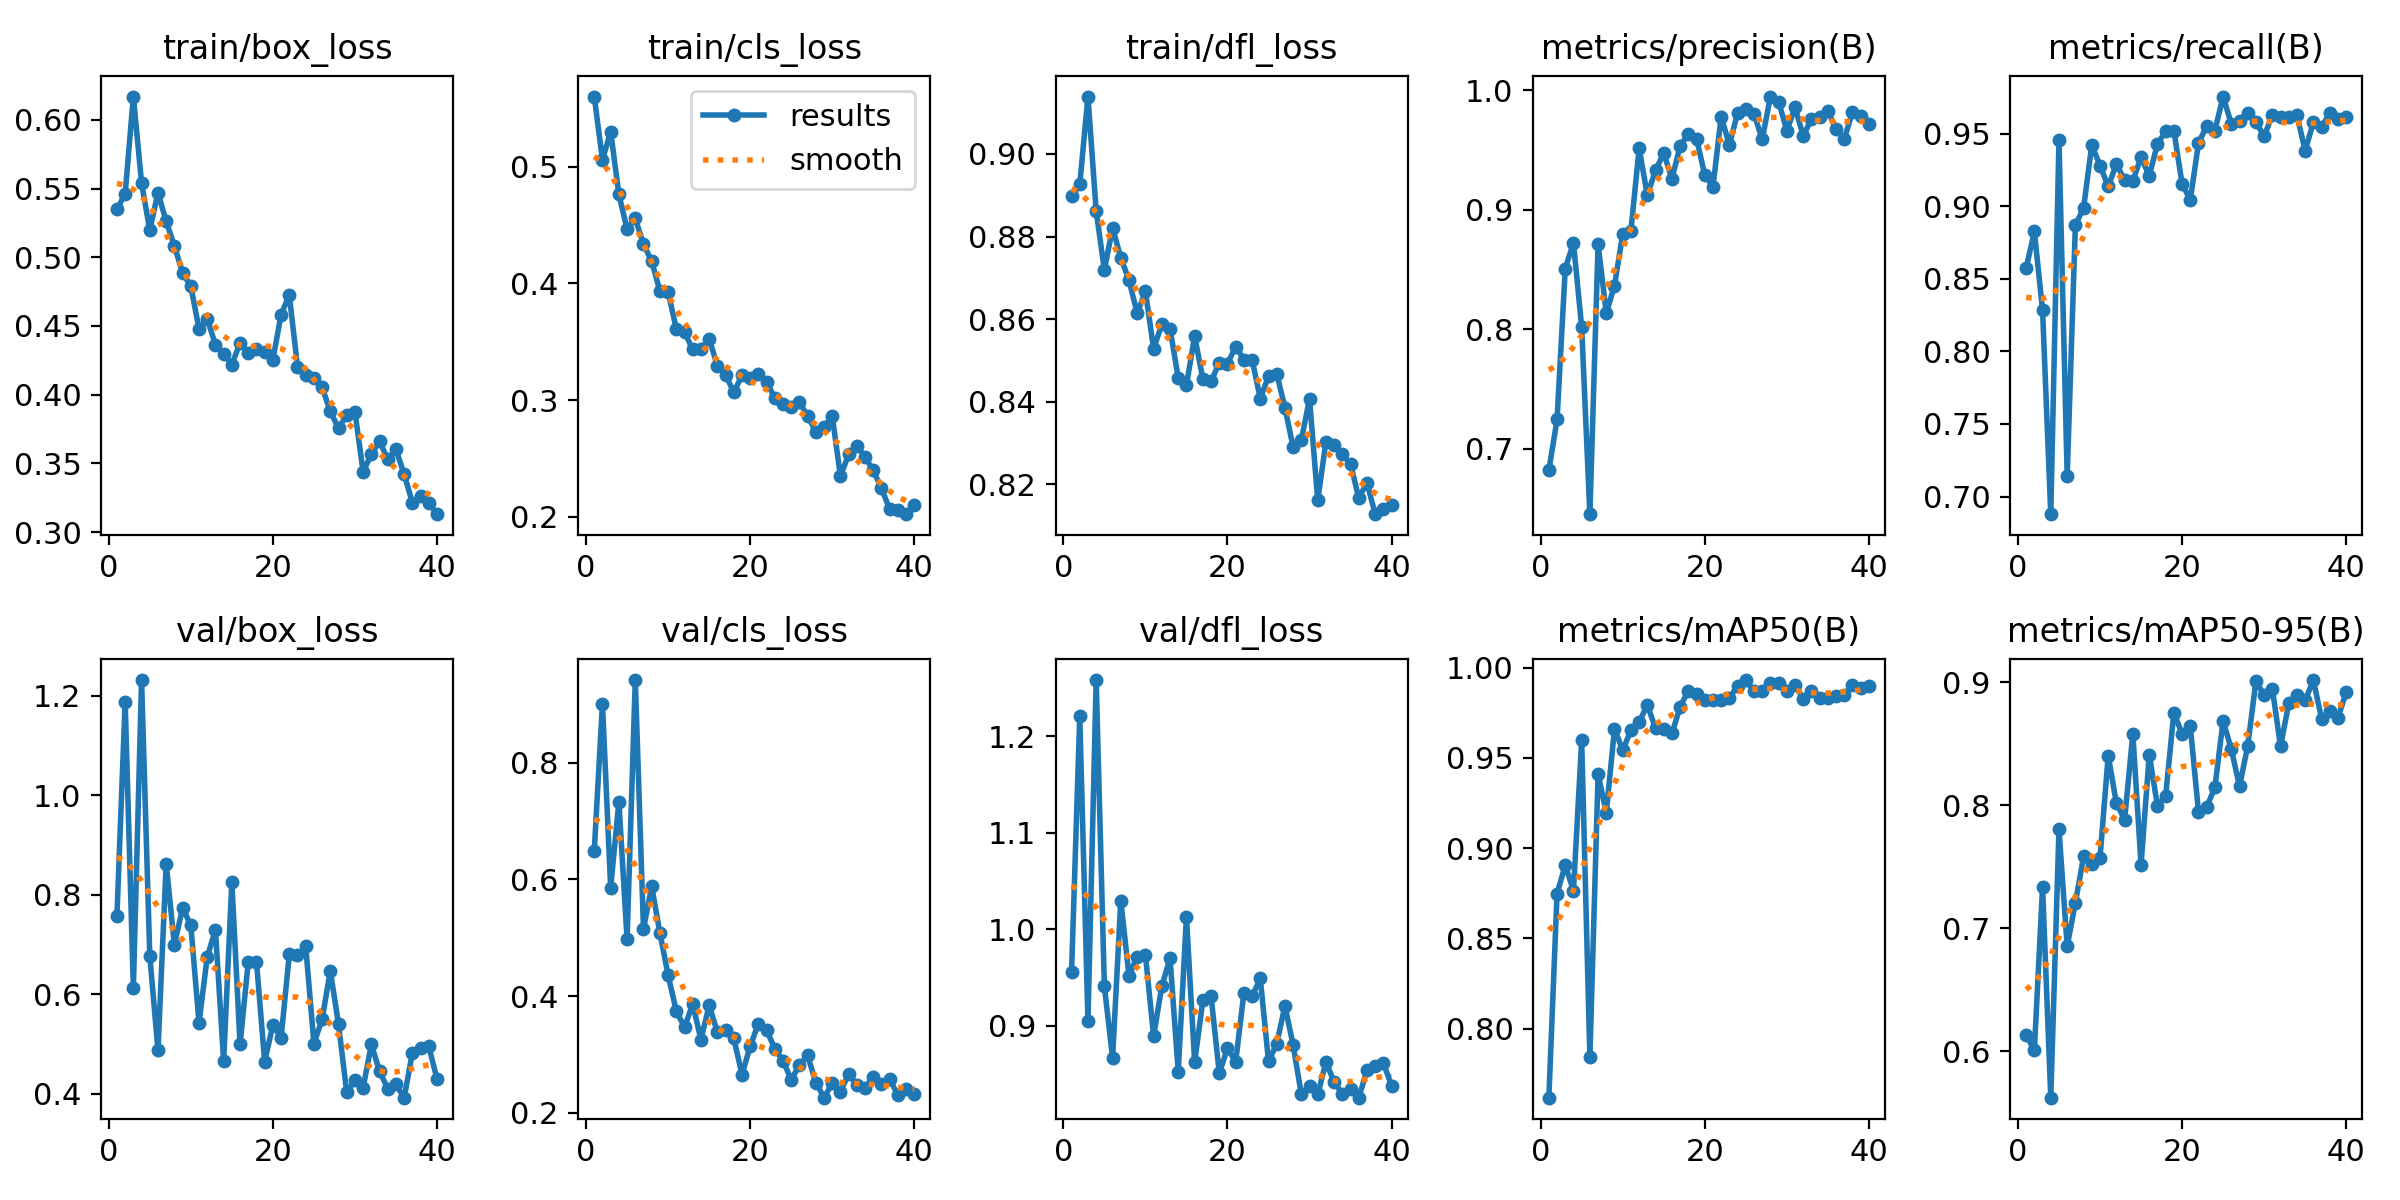

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,414,735 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2219.6±904.0 MB/s, size: 188.4 KB)
val: Scanning /content/por_valor/test/labels.cache... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 3.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.7it/s 1.2s
                   all         20        401      0.994      0.997      0.995       0.95
                    5c         19         69          1      0.986      0.995      0.961
                   10c         19         84      0.997          1      0.995      0.942
                   25c         19         88       0.98          1      0.995      0.948
                   50c         20         93      0.996          1      0.995      0.943
                 1real         17         67    

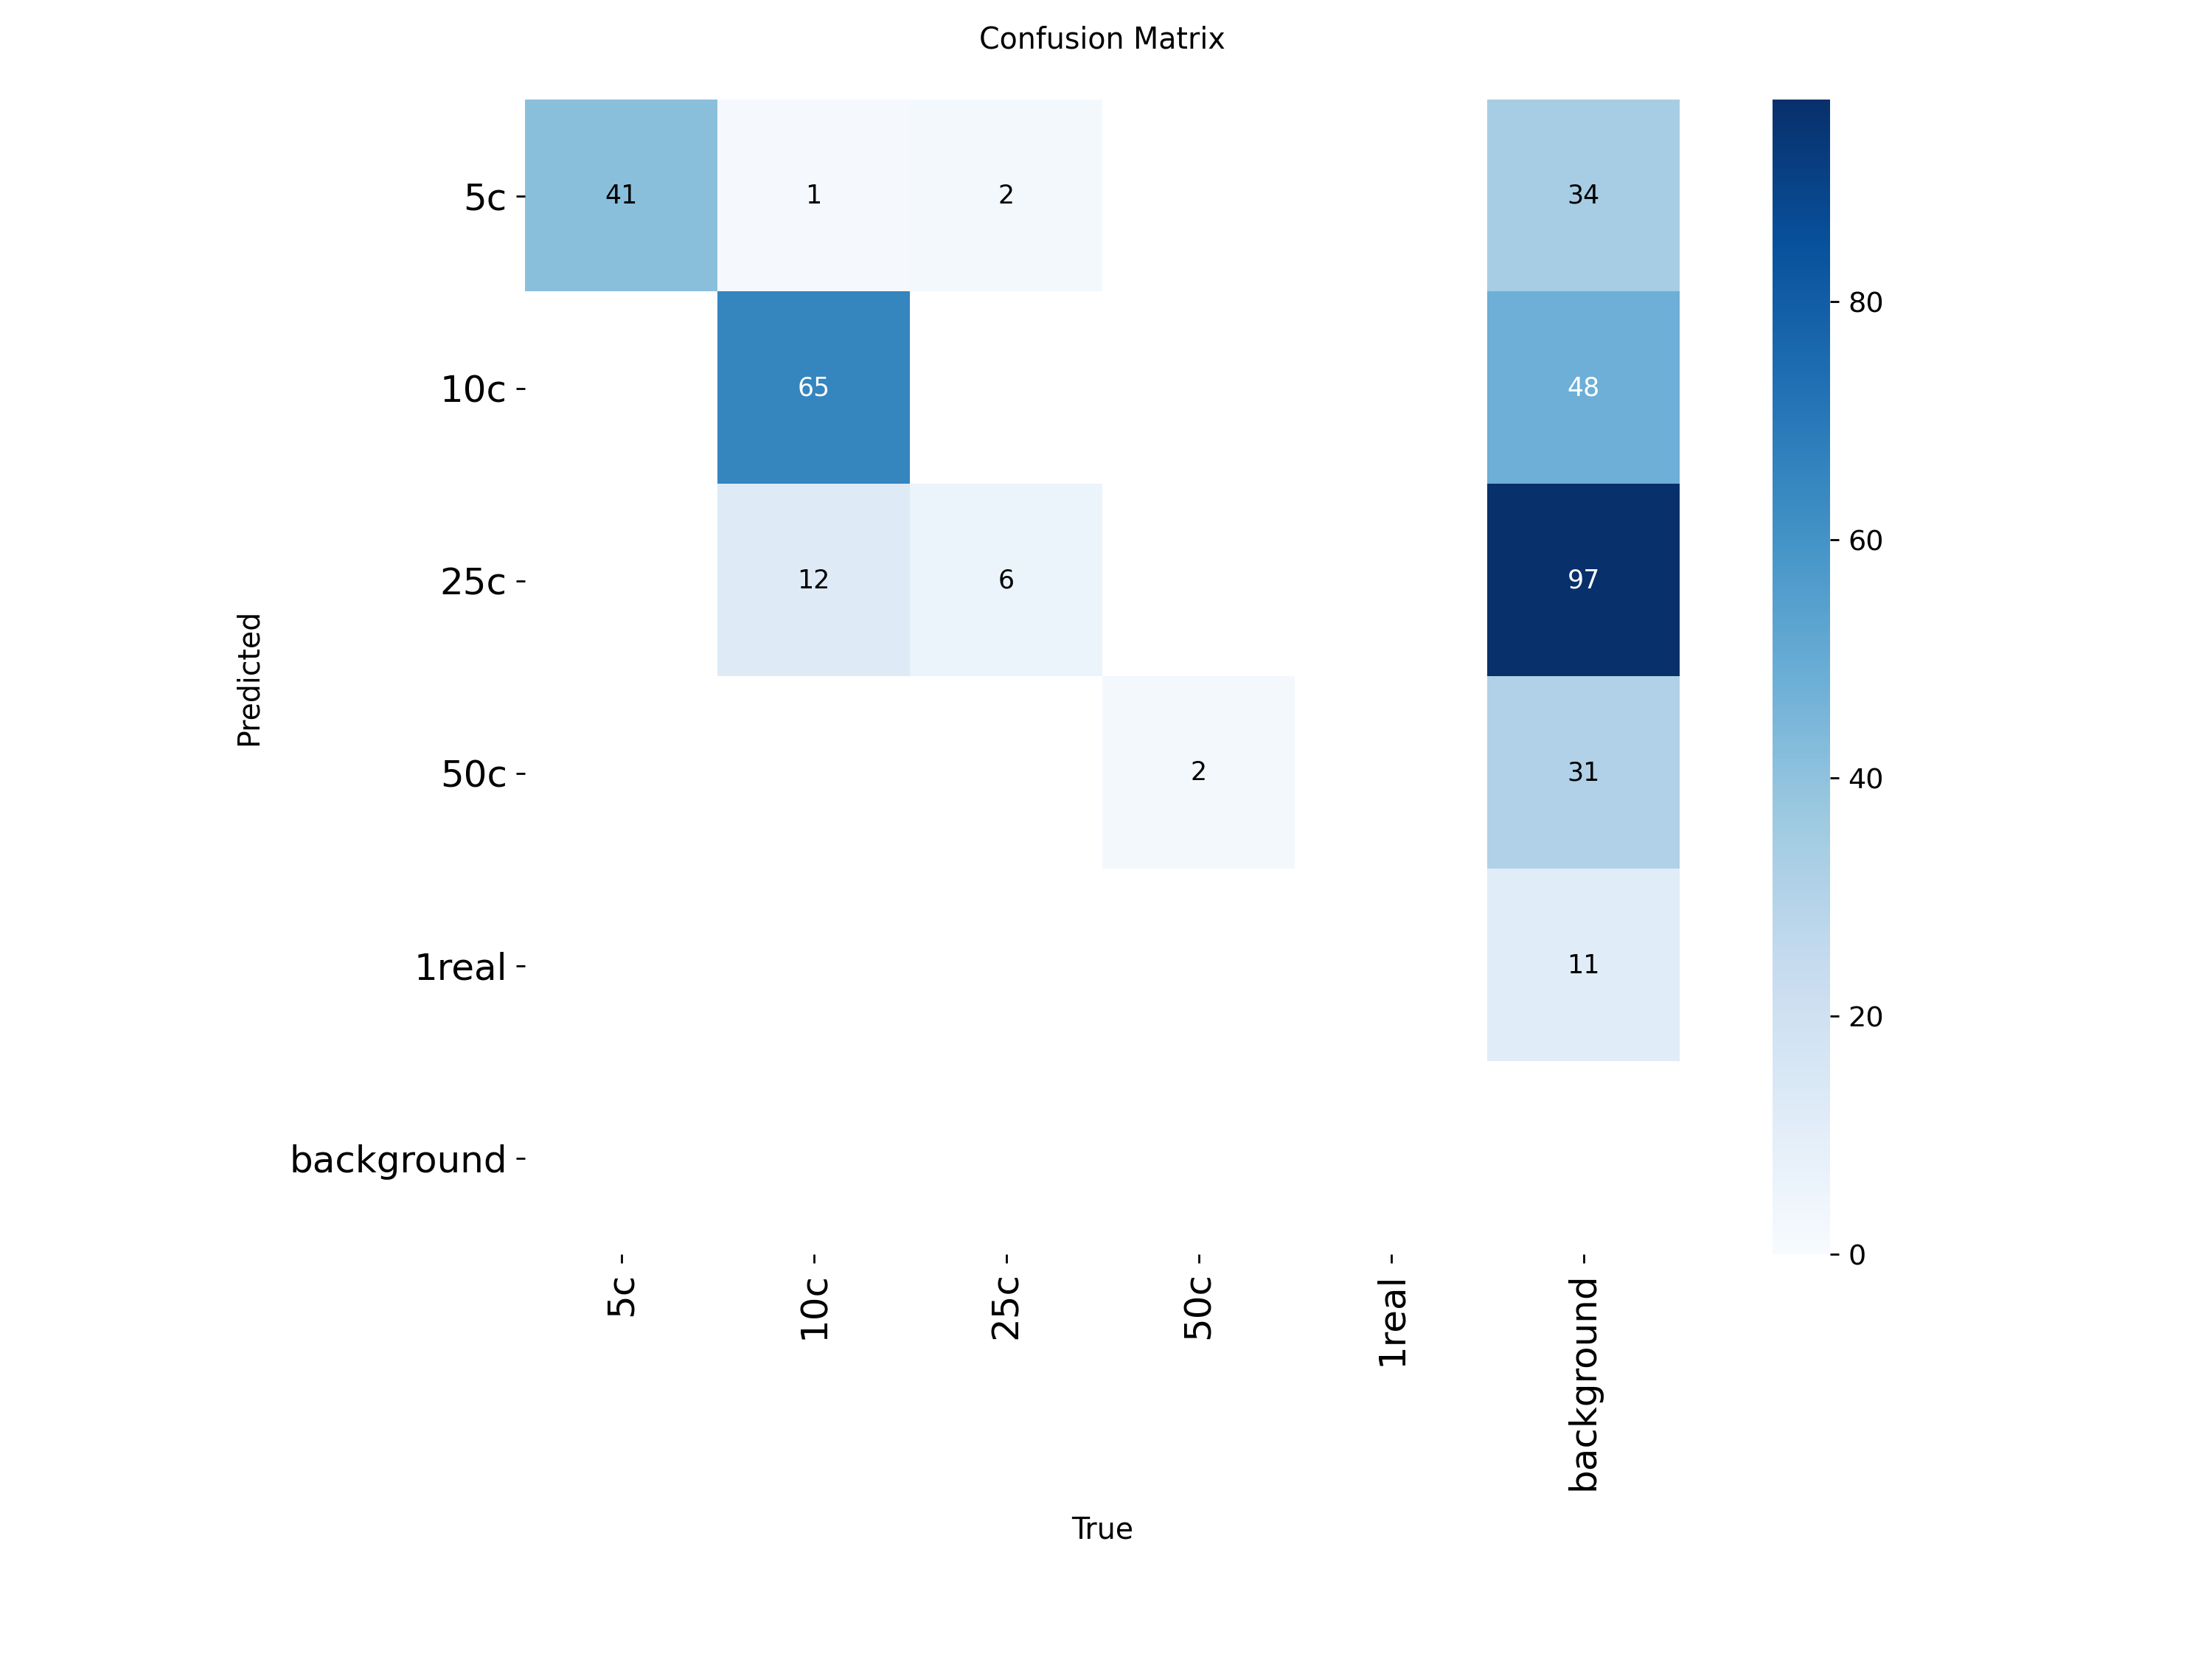

erro médio (R$) na validação por conf: {0.25: np.float64(0.048), 0.4: np.float64(0.048), 0.5: np.float64(0.049), 0.6: np.float64(0.051), 0.7: np.float64(0.046)}
real_valor (teste sintético): conf 0.7 | acurácia por moeda 0.995 | erro médio no total R$ 0.01


,foto,real,previsto,erro,ms
0,/content/por_face/test/images/test_000.jpg,2.15,2.15,0.00,29.617294
1,/content/por_face/test/images/test_001.jpg,4.10,4.10,0.00,30.677766
2,/content/por_face/test/images/test_002.jpg,6.70,6.70,0.00,33.166779
3,/content/por_face/test/images/test_003.jpg,2.90,2.90,0.00,29.163942
4,/content/por_face/test/images/test_004.jpg,1.90,1.90,0.00,29.347454
5,/content/por_face/test/images/test_005.jpg,4.45,4.45,0.00,31.317961
6,/content/por_face/test/images/test_006.jpg,14.65,14.65,0.00,35.607642
7,/content/por_face/test/images/test_007.jpg,11.20,11.15,0.05,42.611723
8,/content/por_face/test/images/test_008.jpg,9.60,9.60,0.00,39.411477
9,/content/por_face/test/images/test_009.jpg,10.95,10.95,0.00,47.819109


real_valor (fotos reais): conf 0.7 | acurácia por moeda 0.860 | erro médio no total R$ 0.24


,foto,real,previsto,erro,ms
0,/content/repo/atividade4/reais/teste/images/10...,1.00,1.05,0.05,24.162668
1,/content/repo/atividade4/reais/teste/images/10...,1.00,1.15,0.15,23.978545
2,/content/repo/atividade4/reais/teste/images/12...,1.20,1.65,0.45,24.605684
3,/content/repo/atividade4/reais/teste/images/12...,1.20,1.65,0.45,25.538957
4,/content/repo/atividade4/reais/teste/images/13...,1.30,0.85,0.45,24.064164
5,/content/repo/atividade4/reais/teste/images/14...,1.45,1.35,0.10,25.659862
6,/content/repo/atividade4/reais/teste/images/15...,1.50,1.65,0.15,23.973984
7,/content/repo/atividade4/reais/teste/images/17...,1.70,2.15,0.45,26.546321
8,/content/repo/atividade4/reais/teste/images/17...,1.75,1.75,0.00,23.964837
9,/content/repo/atividade4/reais/teste/images/75...,0.75,0.90,0.15,25.183617


In [9]:
# Parte do best.pt da 1a etapa (e não do COCO): o modelo já sabe achar e separar moedas, e só precisa se ajustar
# à aparência das fotos reais. Por isso bastam menos épocas, e patience=10 interrompe cedo se a validação real
# parar de melhorar. As demais escolhas (imgsz, rotação, espelhamento) repetem a 1a etapa pelos mesmos motivos.
model = YOLO("/content/runs/por_valor/weights/best.pt")
model.train(data=f"{root}/data.yaml", epochs=40, imgsz=960, batch=16, patience=10,
            degrees=180, flipud=0.5, project="/content/runs", name="real_valor", exist_ok=True)
modelos["real_valor"] = YOLO("/content/runs/real_valor/weights/best.pt")
display(Image("/content/runs/real_valor/results.png", width=900))

# mAP no teste sintético (para comparar com a Parte A) e nas fotos reais de teste. O mAP real também é medido
# para o modelo por valor da 1a etapa, que tem as mesmas classes, para mostrar o ganho da 2a etapa.
metricas["real_valor"] = model.val(data="/content/por_valor/data.yaml", split="test", imgsz=960,
                                   project="/content/runs", name="real_valor_teste", exist_ok=True).box.map50
metricas_reais = {}
for nome in ["por_valor", "real_valor"]:
    m = modelos[nome].val(data=f"{root}/data.yaml", split="test", imgsz=960,
                          project="/content/runs", name=f"{nome}_teste_reais", exist_ok=True)
    metricas_reais[nome] = m.box.map50
    print(f"{nome} nas fotos reais: mAP50 {m.box.map50:.3f} | mAP50-95 {m.box.map:.3f}")
display(Image("/content/runs/real_valor_teste_reais/confusion_matrix.png", width=700))

avaliar_modelo("real_valor", lambda conf: prever_yolo(modelos["real_valor"], conf), "reais_valid")

## Parte B: YOLO + ViT

O YOLO "por valor" da 2a etapa é usado só para localizar as moedas; cada caixa é recortada com 10% de margem e
um Vision Transformer com transfer learning classifica o recorte em 5c, 10c, 25c, 50c ou 1real.
O ViT é treinado com recortes do sintético e das fotos reais de treino, pelo mesmo motivo da 2a etapa do YOLO.

In [10]:
# Recortes das caixas anotadas em pastas por classe (recortes/train/5c/..., recortes/val/5c/...), o formato
# "imagefolder" que o Hugging Face lê direto, com a classe tirada do nome da pasta.
def com_margem(b, tamanho, m=0.10):
    # A margem de 10% inclui a borda inteira da moeda mesmo quando a caixa prevista fica um pouco apertada; a
    # borda e o tamanho relativo ajudam a separar moedas parecidas, como 10c e 25c.
    x1, y1, x2, y2 = b
    dx, dy = (x2 - x1) * m, (y2 - y1) * m
    return (max(0, x1 - dx), max(0, y1 - dy), min(tamanho[0], x2 + dx), min(tamanho[1], y2 + dy))

# Sintético e fotos reais entram juntos; a validação real fica em "val" para que a acurácia acompanhada no
# treino reflita também fotos de verdade.
fontes = [("/content/por_face/train", face["names"], "train"), (f"{REAIS}/treino", CLASSES, "train"),
          ("/content/por_face/valid", face["names"], "val"), (f"{REAIS}/valid", CLASSES, "val")]
for pasta, names, destino in fontes:
    for p in glob.glob(f"{pasta}/images/*"):
        img = PILImage.open(p).convert("RGB")
        for k, (b, c) in enumerate(zip(*rotulos(p, names))):
            os.makedirs(f"/content/recortes/{destino}/{c}", exist_ok=True)
            img.crop(com_margem(b, img.size)).save(f"/content/recortes/{destino}/{c}/{os.path.basename(p)}_{k}.jpg")

for destino in ["train", "val"]:
    print(destino, {c: len(os.listdir(f"/content/recortes/{destino}/{c}")) for c in CLASSES})

train {'5c': 1230, '10c': 978, '25c': 797, '50c': 703, '1real': 656}
val {'5c': 310, '10c': 274, '25c': 197, '50c': 220, '1real': 169}


In [11]:
# Transfer learning do ViT pré-treinado no ImageNet-21k: ele já representa bem texturas e
# formas, e o ajuste ensina só a separar os 5 valores de moeda, o que funciona com poucos milhares de recortes.
import numpy as np
from datasets import load_dataset
from torchvision import transforms
from transformers import AutoImageProcessor, AutoModelForImageClassification, TrainingArguments, Trainer

ds = load_dataset("imagefolder", data_dir="/content/recortes")
labels = ds["train"].features["label"].names
ckpt = "google/vit-base-patch16-224-in21k"
proc = AutoImageProcessor.from_pretrained(ckpt)  # redimensiona para 224x224 e normaliza como no pré-treino
# Augmentation só no treino: rotação qualquer (moeda não tem orientação) e variação de brilho e contraste
# (a luz muda de uma foto para outra), para o ViT não depender dessas condições.
aug = transforms.Compose([transforms.RandomRotation(180), transforms.ColorJitter(0.3, 0.3)])

def prep(batch, treino=False):
    ims = [im.convert("RGB") for im in batch["image"]]
    out = proc([aug(im) for im in ims] if treino else ims, return_tensors="pt")
    out["labels"] = batch["label"]
    return out

# set_transform aplica o pré-processamento na hora de ler cada lote, então a augmentation sorteia uma rotação
# nova a cada época em vez de fixar uma só.
ds["train"].set_transform(lambda b: prep(b, treino=True))
ds["validation"].set_transform(prep)

# A cabeça de classificação do modelo é trocada por uma nova com 5 saídas, uma por valor de moeda.
clf = AutoModelForImageClassification.from_pretrained(
    ckpt, num_labels=len(labels), id2label=dict(enumerate(labels)), label2id={l: i for i, l in enumerate(labels)})

# learning_rate=3e-5: taxa pequena, típica de transfer learning, para ajustar os pesos pré-treinados sem destruir o
# que eles já sabem. 8 épocas bastam porque a acurácia de validação estabiliza antes disso.
args = TrainingArguments("/content/vit-moedas", per_device_train_batch_size=16, num_train_epochs=8,
                         learning_rate=3e-5, eval_strategy="epoch", save_strategy="no",
                         remove_unused_columns=False, report_to="none")
trainer = Trainer(model=clf, args=args, train_dataset=ds["train"], eval_dataset=ds["validation"],
                  data_collator=lambda b: {"pixel_values": torch.stack([x["pixel_values"] for x in b]),
                                           "labels": torch.tensor([x["labels"] for x in b])},
                  compute_metrics=lambda p: {"acuracia": (p.predictions.argmax(-1) == p.label_ids).mean()})
trainer.train()
trainer.save_model("/content/vit-moedas")
proc.save_pretrained("/content/vit-moedas")

Resolving data files:   0%|          | 0/4364 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1170 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

... (3 outputs left out)

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Acuracia
1,No log,0.122792,0.983761
2,0.249810,0.064091,0.993162
3,0.249810,0.041839,0.994872
4,0.031292,0.028139,0.996581
5,0.031292,0.023680,0.997436
6,0.021066,0.035118,0.993162
7,0.021066,0.023419,0.994872
8,0.012565,0.022708,0.995726


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['/content/vit-moedas/preprocessor_config.json']

In [12]:
# Pipeline completo: o YOLO da 2a etapa localiza, cada caixa é recortada com margem, o ViT classifica e os
# valores são somados. A ideia é dividir o trabalho: o YOLO só precisa achar moedas e o ViT, que vê cada moeda
# ampliada para 224x224, decide o valor.
det = modelos["real_valor"]
clf = clf.eval()  # modo de avaliação: desliga o dropout para a previsão ser determinística

def prever_hibrido(conf):
    def prever(p):
        img = PILImage.open(p).convert("RGB")
        # agnostic_nms=True pelo mesmo motivo da Parte A: uma caixa por moeda, qualquer que seja a classe do YOLO
        caixas = det.predict(img, conf=conf, imgsz=960, agnostic_nms=True, verbose=False)[0].boxes.xyxy.tolist()
        if not caixas:
            return [], []
        # todos os recortes da foto vão ao ViT num único lote, que é mais rápido que um recorte por vez
        inp = proc([img.crop(com_margem(b, img.size)) for b in caixas], return_tensors="pt").to(clf.device)
        with torch.no_grad():
            preds = clf(**inp).logits.argmax(-1).tolist()
        return caixas, [clf.config.id2label[i] for i in preds]
    return prever

avaliar_modelo("hibrido", prever_hibrido, "reais_valid")

# mAP da Parte B: só a detecção usa caixas, então mede o YOLO como detector de classe única (moeda ou não)
metricas["hibrido"] = det.val(data="/content/por_valor/data.yaml", split="test", imgsz=960, single_cls=True,
                              project="/content/runs", name="detector_teste", exist_ok=True).box.map50
metricas_reais["hibrido"] = det.val(data=f"{root}/data.yaml", split="test", imgsz=960, single_cls=True,
                                    project="/content/runs", name="detector_teste_reais", exist_ok=True).box.map50

erro médio (R$) na validação por conf: {0.25: np.float64(0.044), 0.4: np.float64(0.044), 0.5: np.float64(0.05), 0.6: np.float64(0.052), 0.7: np.float64(0.049)}
hibrido (teste sintético): conf 0.25 | acurácia por moeda 1.000 | erro médio no total R$ 0.00


,foto,real,previsto,erro,ms
0,/content/por_face/test/images/test_000.jpg,2.15,2.15,0.0,191.068783
1,/content/por_face/test/images/test_001.jpg,4.10,4.10,0.0,192.973161
2,/content/por_face/test/images/test_002.jpg,6.70,6.70,0.0,275.278748
3,/content/por_face/test/images/test_003.jpg,2.90,2.90,0.0,113.082094
4,/content/por_face/test/images/test_004.jpg,1.90,1.90,0.0,150.269658
5,/content/por_face/test/images/test_005.jpg,4.45,4.45,0.0,280.172550
6,/content/por_face/test/images/test_006.jpg,14.65,14.65,0.0,546.163702
7,/content/por_face/test/images/test_007.jpg,11.20,11.20,0.0,479.267793
8,/content/por_face/test/images/test_008.jpg,9.60,9.60,0.0,380.502597
9,/content/por_face/test/images/test_009.jpg,10.95,10.95,0.0,390.534686


hibrido (fotos reais): conf 0.25 | acurácia por moeda 0.946 | erro médio no total R$ 0.10


,foto,real,previsto,erro,ms
0,/content/repo/atividade4/reais/teste/images/10...,1.00,1.15,0.15,193.393124
1,/content/repo/atividade4/reais/teste/images/10...,1.00,1.00,0.00,210.992634
2,/content/repo/atividade4/reais/teste/images/12...,1.20,1.20,0.00,224.629271
3,/content/repo/atividade4/reais/teste/images/12...,1.20,1.35,0.15,220.030459
4,/content/repo/atividade4/reais/teste/images/13...,1.30,0.80,0.50,192.498332
5,/content/repo/atividade4/reais/teste/images/14...,1.45,1.60,0.15,211.112144
6,/content/repo/atividade4/reais/teste/images/15...,1.50,1.50,0.00,213.396799
7,/content/repo/atividade4/reais/teste/images/17...,1.70,1.70,0.00,212.750124
8,/content/repo/atividade4/reais/teste/images/17...,1.75,1.75,0.00,221.080192
9,/content/repo/atividade4/reais/teste/images/75...,0.75,0.75,0.00,186.939948


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,414,735 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1804.4±573.9 MB/s, size: 107.9 KB)
val: Scanning /content/por_valor/test/labels... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 983.4it/s 0.0s
val: New cache created: /content/por_valor/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.6it/s 1.3s
                   all         20        401          1          1      0.995      0.946
                    5c         20        401          1          1      0.995      0.946
Speed: 8.2ms preprocess, 16.9ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to /content/runs/detector_teste
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,414,735

## Comparação: teste sintético e fotos reais

In [13]:
# Tabela da seção 4.6, com colunas extras para as fotos reais. O modelo por face não tem mAP nas fotos reais
# porque elas não têm a face anotada (fica vazio).
nomes = {"por_valor": "A: YOLO (1 classe por valor)", "por_face": "A: YOLO (classe por face)",
         "real_valor": "A: YOLO por valor + 2a etapa com fotos reais", "hibrido": "B: YOLO + ViT"}
pd.DataFrame([{"Solução": nomes[k], "mAP@0.5": round(metricas[k], 3),
               "Acurácia por moeda": round(resultados[k]["acuracia"], 3),
               "Erro médio no total (R$)": round(resultados[k]["erro_medio"], 2),
               "Tempo (ms/img)": round(resultados[k]["ms"], 1), "conf": confs[k],
               "mAP@0.5 (reais)": round(metricas_reais[k], 3) if k in metricas_reais else None,
               "Acurácia por moeda (reais)": round(reais[k]["acuracia"], 3),
               "Erro médio no total (reais, R$)": round(reais[k]["erro_medio"], 2)} for k in nomes])

,Solução,mAP@0.5,Acurácia por moeda,Erro médio no total (R$),Tempo (ms/img),conf,mAP@0.5 (reais),Acurácia por moeda (reais),"Erro médio no total (reais, R$)"
0,A: YOLO (1 classe por valor),0.995,0.965,0.07,27.6,0.70,0.541,0.256,1.55
1,A: YOLO (classe por face),0.995,1.000,0.00,27.4,0.25,NaN,0.519,1.10
2,A: YOLO por valor + 2a etapa com fotos reais,0.995,0.995,0.01,34.2,0.70,0.926,0.860,0.24
3,B: YOLO + ViT,0.995,1.000,0.00,291.7,0.25,0.995,0.946,0.10


## Análise de erros e demonstração

Usa a solução com menor erro médio nas fotos reais. Cada foto é desenhada com as caixas previstas, o valor de
cada moeda, o total previsto e o total real. As 3 fotos que mais erraram em cada conjunto (fotos reais e teste
sintético) são salvas em `/content/erros/` para o relatório, e as 3 fotos de demonstração em `/content/demo/`.

solução usada: B: YOLO + ViT
/content/erros/reais/130_1477861908.jpg previsto R$ 0.80 | real R$ 1.30


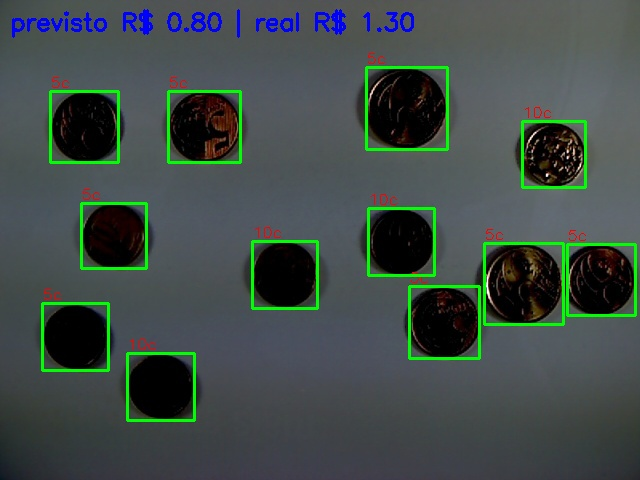

/content/erros/reais/100_1477860900.jpg previsto R$ 1.15 | real R$ 1.00


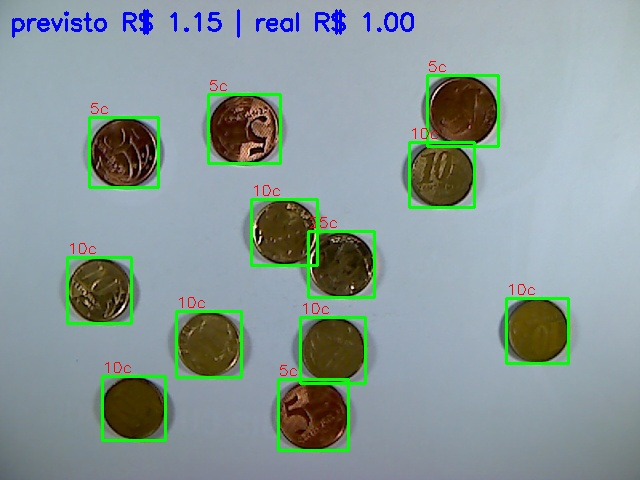

/content/erros/reais/145_1479428850.jpg previsto R$ 1.60 | real R$ 1.45


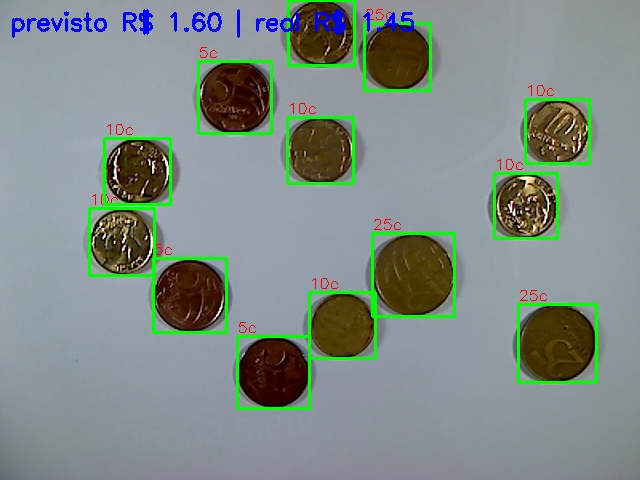

/content/erros/test/test_000.jpg previsto R$ 2.15 | real R$ 2.15


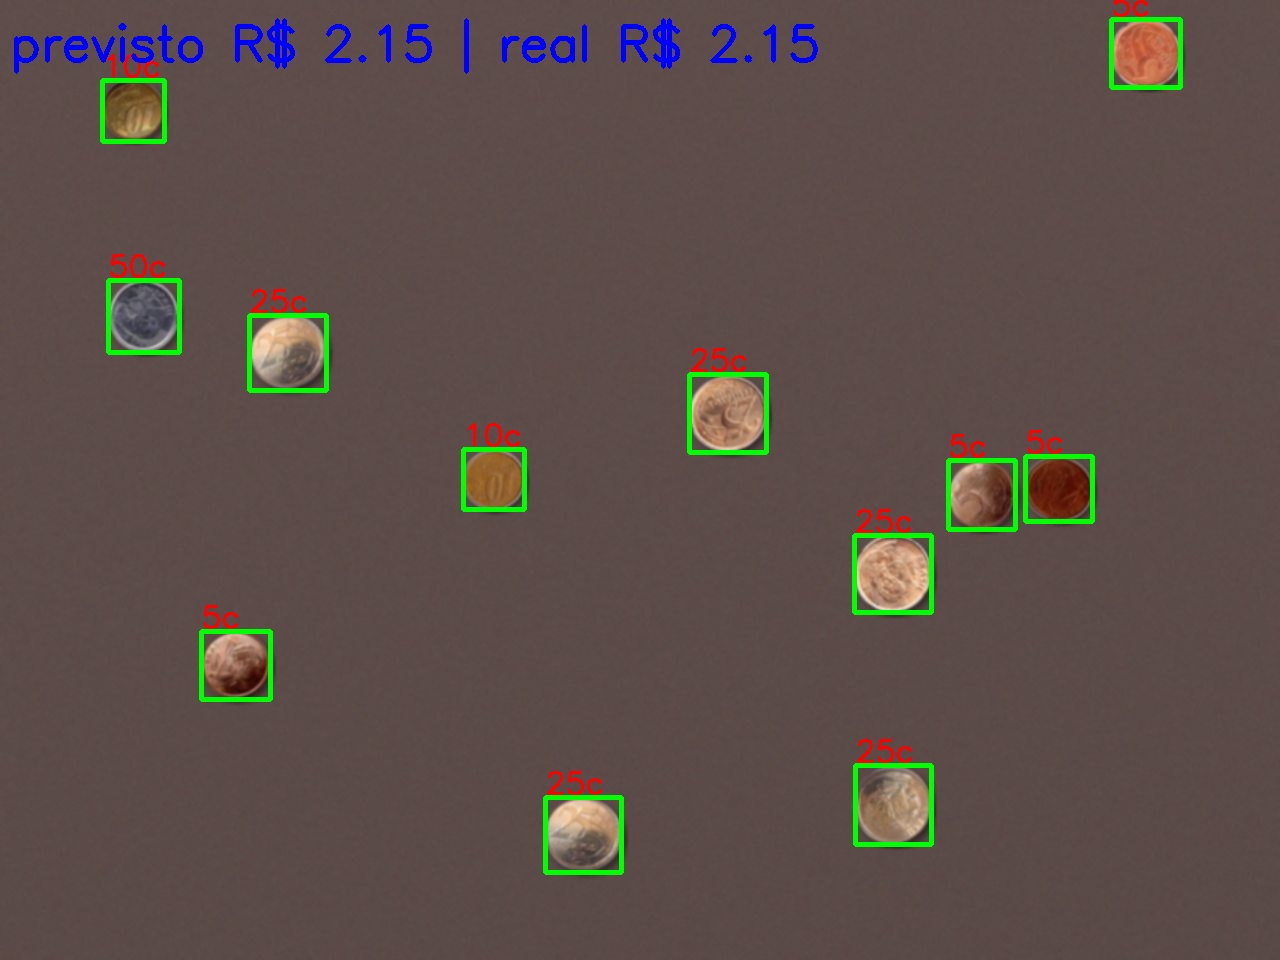

/content/erros/test/test_001.jpg previsto R$ 4.10 | real R$ 4.10


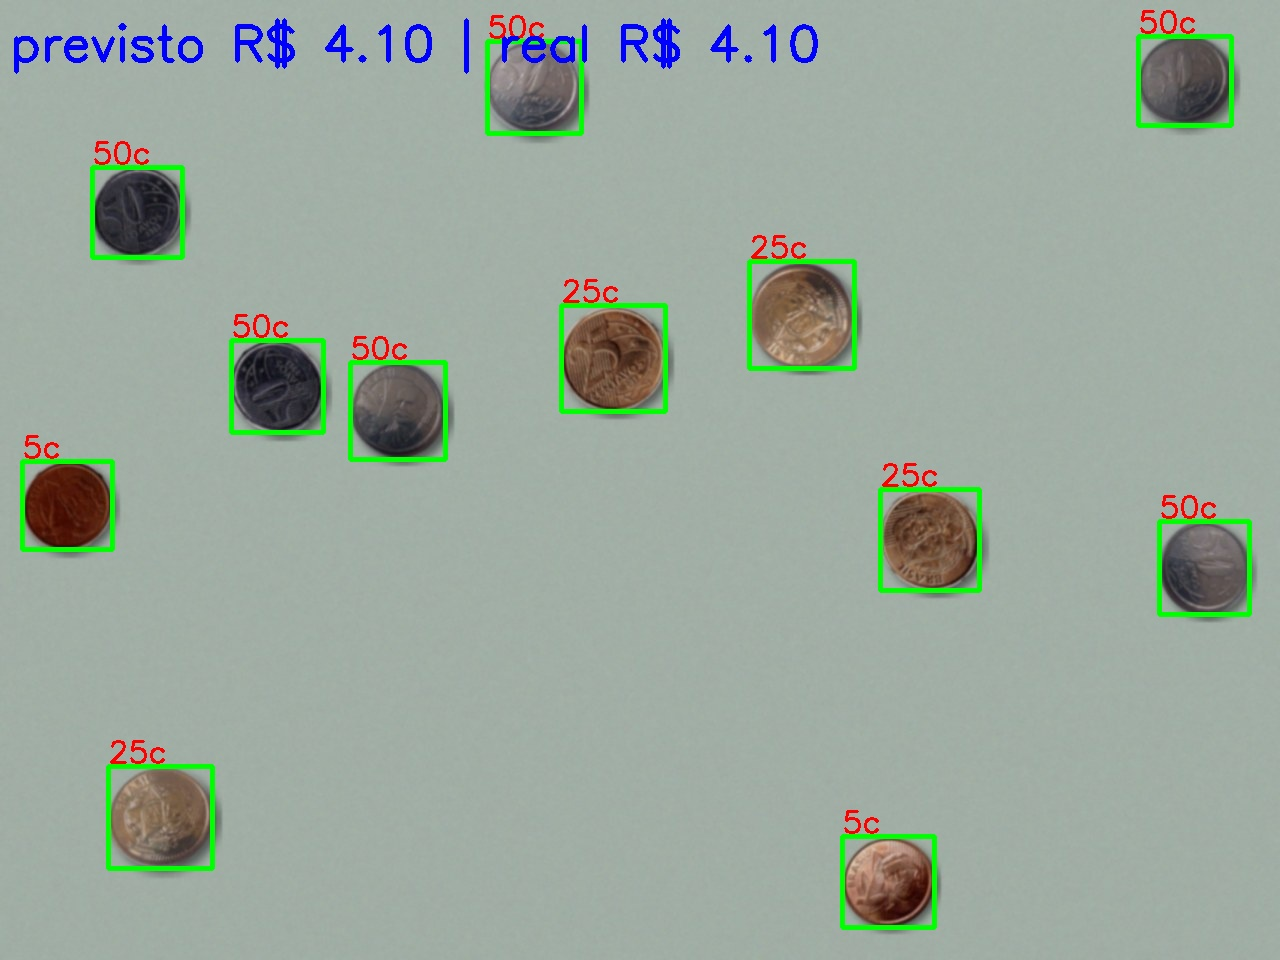

/content/erros/test/test_002.jpg previsto R$ 6.70 | real R$ 6.70


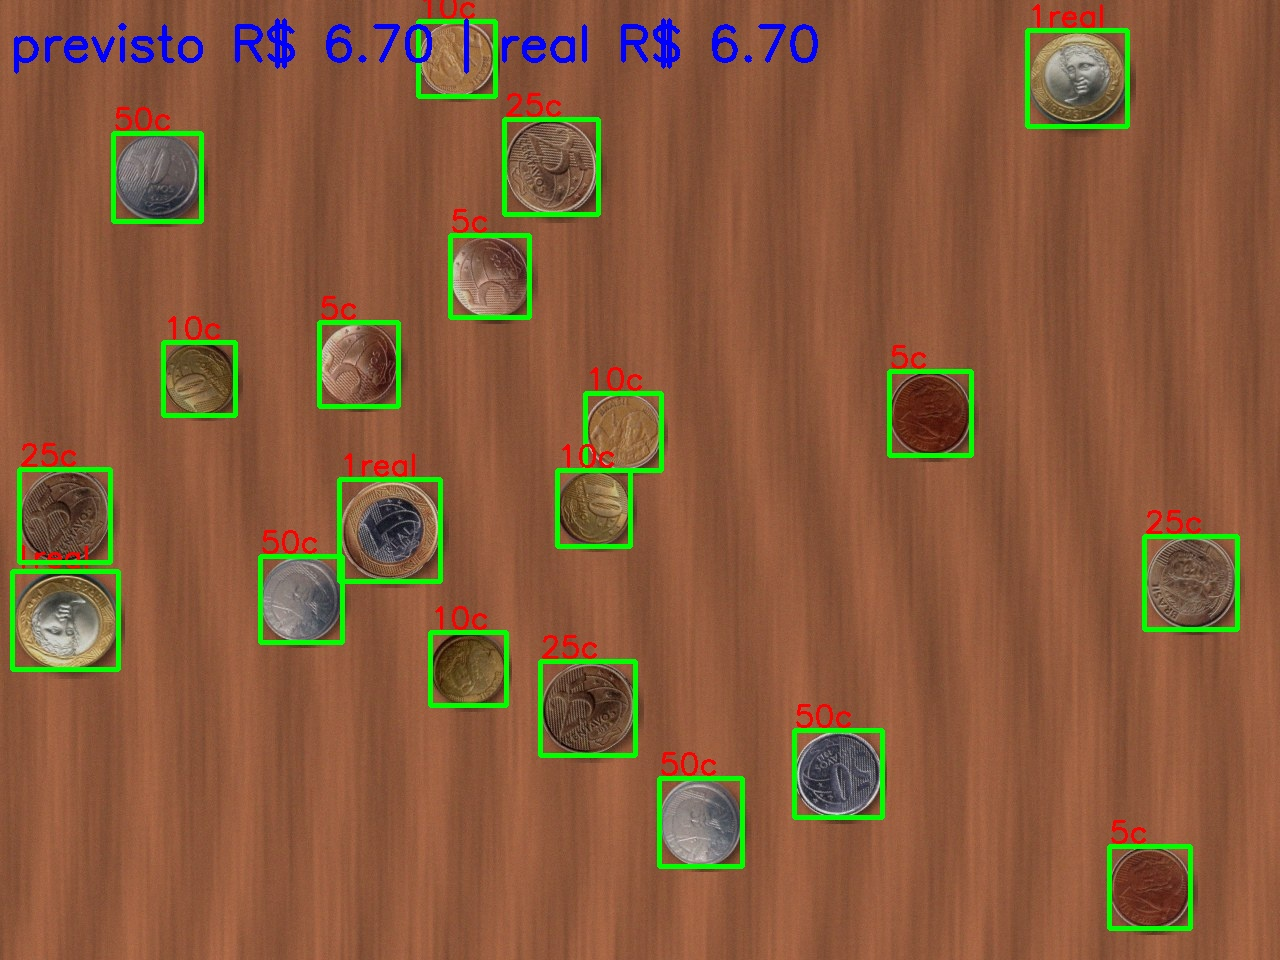

In [14]:
import cv2

# A solução escolhida é a de menor erro nas fotos reais, porque é o uso pretendido (fotos de verdade).
melhor = min(reais, key=lambda k: reais[k]["erro_medio"])
print("solução usada:", nomes[melhor])

def desenhar(p, conj, destino):
    # Desenha as caixas e o valor previsto de cada moeda, com o total previsto e o real no topo, para mostrar no
    # relatório onde o modelo erra (moeda perdida, caixa a mais ou valor trocado).
    caixas, classes = previsores[melhor](p)
    real = sum(VALORES[c] for c in rotulos(p, CONJUNTOS[conj][1])[1])
    previsto = sum(VALORES[c] for c in classes)
    img = cv2.imread(p)
    e = img.shape[1] / 640  # espessura e fonte proporcionais à largura, para ficarem legíveis em qualquer foto
    for (x1, y1, x2, y2), c in zip(caixas, classes):
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), max(1, int(2 * e)))
        cv2.putText(img, c, (int(x1), int(y1) - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5 * e, (0, 0, 255), max(1, int(e)))
    cv2.putText(img, f"previsto R$ {previsto:.2f} | real R$ {real:.2f}", (10, int(30 * e)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8 * e, (255, 0, 0), max(1, int(2 * e)))
    os.makedirs(destino, exist_ok=True)
    saida = f"{destino}/{os.path.basename(p)}"
    cv2.imwrite(saida, img)
    print(saida, f"previsto R$ {previsto:.2f} | real R$ {real:.2f}")
    display(Image(saida, width=600))

# Análise de erros: as 3 fotos com maior erro no total em cada conjunto, que são as que mais ensinam sobre as
# limitações do modelo.
for conj, r in [("reais", reais[melhor]), ("test", resultados[melhor])]:
    for p in r["fotos"].sort_values("erro", ascending=False)["foto"][:3]:
        desenhar(p, conj, f"/content/erros/{conj}")

/content/demo/130_1477863000.jpg previsto R$ 1.30 | real R$ 1.30


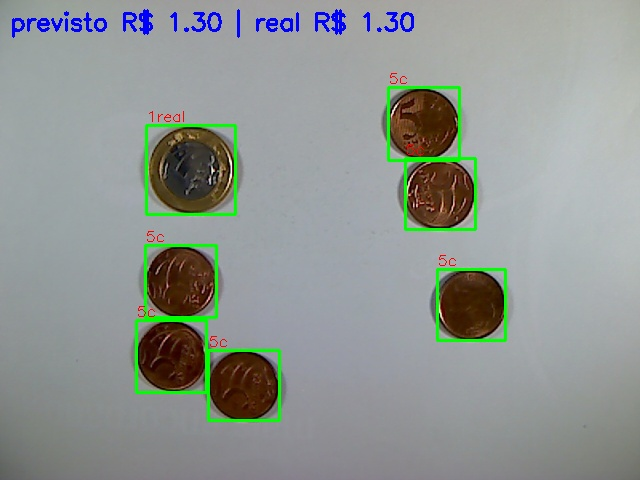

/content/demo/150_1477864224.jpg previsto R$ 1.50 | real R$ 1.50


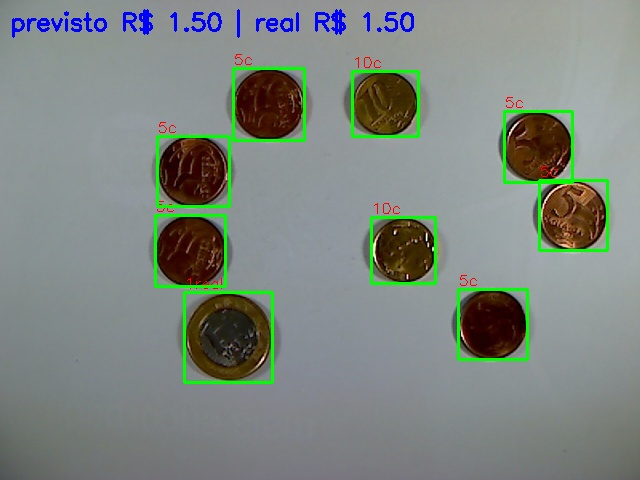

/content/demo/80_1477850610.jpg previsto R$ 0.80 | real R$ 0.80


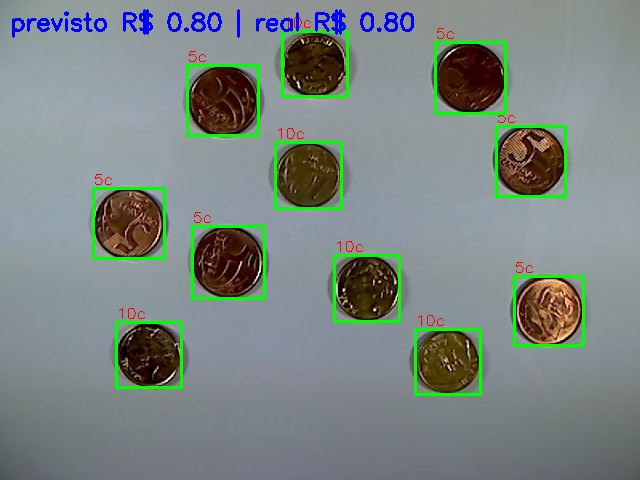

In [15]:
# Demonstração: 3 fotos reais de mesas diferentes, de sessões que não estão no treino, na validação nem no teste
for p in sorted(glob.glob(f"{REAIS}/demo/images/*")):
    desenhar(p, "demo", "/content/demo")

In [16]:
# Baixa num zip os pesos (best.pt de cada YOLO e a pasta do ViT), os gráficos, o dataset gerado e as imagens de
# erros e da demonstração, para o relatório e para usar o modelo fora do Colab (uso.py).
from google.colab import files

!cd /content && zip -qr runs.zip runs vit-moedas por_face erros demo
files.download("/content/runs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>